# Ajedrez online — Entrega 3: modelado del resultado antes y durante la partida

**Proyecto Integrador — Ciencia de Datos, UTN FRM 2026**

**Pregunta.** ¿Qué tan bien se predice quién gana una partida de ajedrez online, y cuánto le falta para terminar, **antes de que empiece y a medida que avanza**?

**Qué cambió desde la Entrega 2.** En la Entrega 2 el dataset no tenía variables reales para predecir: sólo el rating posterior, que trae el resultado adentro. Ahora cada fila es una partida vista en un momento dado (partida × corte de plies), con la posición y los relojes de ese momento, el rating **previo** reconstruido sin fuga y la forma reciente de cada jugador. El objetivo sigue siendo `resultado`.

**Qué hay en este notebook.** El modelado de la Entrega 3:

1. el planteo: métrica, piso y validación, declarados antes de entrenar;
2. tres modelos comparados con la misma validación cruzada;
3. qué pasa si la validación se arma de otra forma;
4. el ajuste del elegido;
5. la decisión sobre la clase chica;
6. las columnas que no sirvieron, y los ratings de los rivales (una corrección posterior a la Entrega 3);
7. el modelo final, congelado por CV y medido en test, con su reutilización declarada en §8.

Después, la comprobación de que el modelo sirve en cualquier jugada, la duración restante como objetivo secundario y el modelo guardado para la app de la Entrega 4.

El notebook 03 fue una exploración: un modelo por corte, una sola partición y decisiones tomadas mirando el test. Acá todo lo que se elige se elige con validación cruzada sobre train, y se entrena **un solo modelo** con el corte como columna, que es el que va a usar la app.

**Fuente.** El Parquet tidy (`partidas_ajedrez_clean.parquet`) y la tabla de cortes (`partidas_cortes.parquet`, un corte cada 5 plies del 0 al 120) que genera el DAG, más el rating previo y la forma reciente reconstruidos desde los JSON crudos (incluido el rating de cada rival que aparece en ellos). Corre con **Restart & Run All**, con la semilla del config. La última celda informa el tiempo medido en esta máquina; la validación y las ablaciones requieren decenas de minutos.

## 1 · Planteo

Cuatro decisiones, tomadas antes del primer modelo.

**Qué se predice.** `resultado` (Gana Blancas / Empate / Gana Negras) en cada corte, una clasificación de tres clases. Una fila es una partida vista después de `corte_ply` medio-movimientos: el 0 es antes de mover, y llega hasta el 120. Con un solo modelo y el corte como columna, la pregunta "antes y durante" es una sola curva.

**La métrica: log-loss.** La app muestra **probabilidades** jugada a jugada, y el error caro es mostrar 85 % de victoria blanca en una partida que ganan las negras. La log-loss mide exactamente eso: cuánta probabilidad le dio el modelo a lo que efectivamente pasó, y castiga más cuanto más seguro estaba de lo contrario. La accuracy no lo ve, porque para ella es lo mismo acertar con 51 % que con 99 %. Las clases están desparejas (el empate es 6,81 % por partida), así que se informan además el **F1 macro**, que ve a la clase chica, y el **recall de Empate**.

**El piso.** `DummyClassifier(strategy="prior")`: siempre las proporciones de train, sin mirar ninguna columna. Se mide con la misma validación que todo lo demás.

**La validación imita el uso.** Las filas se repiten de tres formas, y cada una pesa en cómo se arman los pedazos:

| Las filas se repiten… | Cómo se usa el modelo | Cómo se arman los pedazos |
|---|---|---|
| por **partida**: hasta 25 cortes de la misma partida, con el mismo resultado | se predice una partida que no se vio | una partida nunca queda de los dos lados |
| en el **tiempo** | se predicen las partidas que vienen | se entrena con lo anterior y se valida con lo posterior |
| por **jugador**: hasta 1.000 partidas de cada cuenta | la app predice las próximas partidas de jugadores que ya tienen historial (de ahí salen su rating previo y su forma) | el mismo jugador puede estar de los dos lados, a propósito |

En concreto:

- **Test.** Las partidas que empiezan después del percentil 80 de `StartTime`. Train son las que terminaron antes, y las que cruzan ese momento se descartan.
- **Validación cruzada dentro de train.** `TimeSeriesSplit` de 5 pedazos sobre las **partidas ordenadas por inicio**, que después se expanden a sus cortes (`src/model_validation.py`). Se le pasa a `cross_validate` y a `GridSearchCV` como `cv=`.
- **Qué pasa si se arman distinto.** La sección 4 mide qué pasa si los pedazos se arman al azar sobre filas, y qué pasa con jugadores que el modelo nunca vio.
- **Costo.** Train tiene 1,24 millones de filas. La comparación, la grilla y las pruebas de columnas usan una muestra del 25 % de las **partidas** de train (no de las filas), con la semilla del config. El modelo final se entrena con todo train.

**Todo el historial del modelo, adentro del pipeline.** El primer paso es `PlayerHistoryTransformer` (`BaseEstimator` + `TransformerMixin`, en `src/history_transformer.py`). Recibe las observaciones individuales del historial de cada lado, el ritmo y el inicio actual. Calcula rating previo, forma y estilo con cierres **estrictamente anteriores** a ese inicio, excluyendo la partida actual, las solapadas, los cierres simultáneos y las futuras. Después se ajustan imputación, escalado y codificación dentro de cada fold. `fit` no conserva los historiales ni el target; las estadísticas de ventanas se consultan de nuevo en `transform`, igual que en la app. El armado de los payloads sólo lee y normaliza observaciones individuales; no agrega columnas del modelo.

La cobertura de historial se calcula por separado sólo para describir los datos. Las entradas de CV y del modelo final llevan NaN en las derivadas y los historiales individuales, para que ningún agregado externo eluda el transformador. Las tasas de matchup se conservan como candidata de ablación, calculadas causalmente por el pipeline de datos; si se descartaron en §7, no forman parte del objeto final.

**Corrección de una suposición anterior.** Ordenar por cierre y usar `shift()` no aseguraba que la partida anterior hubiera terminado antes del inicio actual. La sección 2 cuantifica los casos que no cumplían esa condición. Esta corrida repite entrenamiento y validación con el filtro estricto; no cambia ninguna regla de selección mirando el test. Los tests cubren ventanas, igualdad de timestamps, solapamientos y agregar futuro sin alterar el pasado.

**Reglas para decidir**, fijadas antes de ver los números. Comparan la log-loss **pedazo a pedazo**, porque los cinco pedazos son los mismos para todos los modelos:

- **Modelo.** Uno más complejo reemplaza a la regresión logística sólo si le gana por más que el desvío de la diferencia. Si los dos ensambles le ganan y entre ellos la diferencia no supera su desvío, queda el más rápido de entrenar.
- **Hiperparámetros.** La configuración de menor log-loss media en la grilla.
- **Clase chica.** `class_weight="balanced"` entra sólo si mejora la log-loss por más que el desvío de la diferencia.
- **Columnas.** Un grupo entra si mejora la log-loss global o la del corte 0 por más que el desvío de la diferencia, sin empeorar la otra por más que su desvío. Un grupo sale si quitarlo mejora de la misma forma.

In [1]:
from pathlib import Path
import json
import sys
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, log_loss, make_scorer, mean_absolute_error, recall_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.model_validation import temporal_game_folds
from src.player_selection import load_selection
from src.predict import (
    CATEGORICAL, CLOCKS, FORM, LIVE, MODEL_PATH, POSITION, POSITION_GROUPS, PRE_GAME, RESULT_ORDER, STYLE,
    cargar_modelo, model_frame, model_input_frame, predecir,
)
from src.history_transformer import (
    HISTORY_FEATURES, HISTORY_INPUTS, RATING_AGE, RATING_RELATIVE, PlayerHistoryTransformer, attach_player_histories,
    player_history_payloads,
)
from src.live_features import game_cut_features
from src.utils import load_config

config = load_config(PROJECT_ROOT / "config" / "config.yaml")
RANDOM_STATE = config["processing"]["random_state"]
CUTS = config["live_prediction"]["cortes_ply"]
REFERENCE_CUTS = config["live_prediction"]["cortes_referencia"]
# Model comparison, grid and column tests run on this share of the training GAMES (not rows).
CV_GAME_FRACTION = 0.25
N_SPLITS = 5
NOTEBOOK_START = time.perf_counter()

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 2 · Datos y partición

La tabla de cortes sólo guarda lo que cambia jugada a jugada. El contexto fijo de la partida se une desde el tidy por `GameUrl` (muchos a uno, con su assert de conteo): el ritmo, el control de tiempo, el torneo, el rating previo, la forma reciente y el matchup de apertura. El matchup se lee de los plies 1 y 2, así que en el corte 0 todavía es una jugada futura: ahí queda "aún no jugado", y sus tasas, vacías. `jugador` es la cuenta seleccionada de la partida; no es una columna del modelo, sólo agrupa para la sección 4.

In [2]:
games = pd.read_parquet(PROJECT_ROOT / config["paths"]["clean_parquet"])
cuts = pd.read_parquet(PROJECT_ROOT / config["paths"]["cortes_parquet"])
assert sorted(cuts["corte_ply"].unique()) == sorted(CUTS), "La tabla de cortes no coincide con live_prediction.cortes_ply"

usernames = load_selection(PROJECT_ROOT / config["player_selection"]["selection_path"])
template = config["chess_com"]["raw_filename_template"]
raw_paths = {u: PROJECT_ROOT / config["paths"]["raw_dir"] / template.format(username=u) for u in usernames}
histories = player_history_payloads(raw_paths, games[["GameUrl", "StartTime"]])
# Same files, plus a rating-only observation of each opponent (tested in section 7).
rival_histories = player_history_payloads(raw_paths, games[["GameUrl", "StartTime"]], rivales=True)
games = attach_player_histories(games, histories)
# Only for describing coverage/range; model inputs contain no aggregated history columns.
observed_history = PlayerHistoryTransformer(HISTORY_FEATURES).fit_transform(games)

# The selected account (white when both are selected): grouping only, never a predictor.
selected = {u.lower() for u in usernames}
white_selected = games["White"].str.lower().isin(selected)
games["jugador"] = games["White"].str.lower().where(white_selected, games["Black"].str.lower())
assert games["jugador"].isin(selected).all(), "Una partida sin cuenta seleccionada"

MATCHUP = ["matchup_apertura", "tasa_blancas_hist", "tasa_tablas_hist", "tasa_negras_hist"]
LEAKY = [
    "WhiteElo", "BlackElo", "diferencia_elo", "elo_promedio", "nivel_promedio", "es_sorpresa",
    "Termination", "cantidad_jugadas", "EndTime", "ECO", "Opening", "familia_apertura",
]
assert not set(LEAKY) & set(PRE_GAME + LIVE + POSITION + FORM + STYLE + MATCHUP), "Una columna con fuga quedó entre las candidatas"

context_columns = ["GameUrl", "StartTime", "EndTime", "jugador", "White", "Black", *PRE_GAME, *FORM, *STYLE, *MATCHUP, *HISTORY_INPUTS[1:]]
rows_before = len(cuts)
data = cuts.merge(games.reindex(columns=context_columns), on="GameUrl", how="left", validate="many_to_one")
assert len(data) == rows_before, "Fan-out detectado al unir el contexto de la partida"
# matchup_apertura is read from plies 1 and 2: at cut 0 it is still a future move, and so are its rates.
not_played = data["corte_ply"] < 2
data["matchup_apertura"] = data["matchup_apertura"].astype(str).where(~not_played, "aún no jugado")
data.loc[not_played, MATCHUP[1:]] = np.nan
print(f"Filas (partida, corte): {len(data):,} de {data['GameUrl'].nunique():,} partidas, {data['corte_ply'].nunique()} cortes")

coverage = pd.Series({
    "rating previo de blancas": observed_history["elo_blancas_previo"].notna().mean(),
    "rating previo de negras": observed_history["elo_negras_previo"].notna().mean(),
    "forma reciente de blancas": observed_history["forma_ultimas10_blancas"].notna().mean(),
    "forma reciente de negras": observed_history["forma_ultimas10_negras"].notna().mean(),
}, name="% de partidas").mul(100)
display(coverage.to_frame().round(1))
# Audit of the former shift-only reconstruction, without using those values as features.
unsafe = 0
modeled_urls = set(games["GameUrl"])
for payload in histories.values():
    previous_end = {}
    for end, rhythm, rating, score, timeout, clock, start, url, *_ in payload:
        if url in modeled_urls and rhythm in previous_end and previous_end[rhythm] >= start:
            unsafe += 1
        previous_end[rhythm] = end
print(f"Anomalía del historial anterior: {unsafe:,} observaciones propias con cierre previo >= inicio actual; excluidas por el transformador")


2026-10-23 09:42:16 - src.rating_history - INFO - Observaciones de rating: 101094 propias, 100548 sólo rating de rivales (546 duplicadas descartadas).


Filas (partida, corte): 1,559,622 de 100,396 partidas, 25 cortes


,% de partidas
rating previo de blancas,50.100
rating previo de negras,49.900
forma reciente de blancas,48.900
forma reciente de negras,48.800


Anomalía del historial anterior: 1,345 observaciones propias con cierre previo >= inicio actual; excluidas por el transformador


In [3]:
split_time = games["StartTime"].quantile(0.8)
train_games = set(games.loc[games["EndTime"] < split_time, "GameUrl"])
test_games = set(games.loc[games["StartTime"] >= split_time, "GameUrl"])
assert not train_games & test_games

data["particion"] = np.select(
    [data["GameUrl"].isin(train_games), data["GameUrl"].isin(test_games)], ["train", "test"], default="descartada"
)
train = data[data["particion"] == "train"].reset_index(drop=True)
test = data[data["particion"] == "test"].reset_index(drop=True)
print(f"Corte temporal: {split_time:%Y-%m-%d %H:%M} UTC")
print(f"Train: {len(train_games):,} partidas, {len(train):,} filas · Test: {len(test_games):,} partidas, {len(test):,} filas · "
      f"descartadas por cruzar el corte: {len(games) - len(train_games) - len(test_games)} partidas")
display(
    pd.crosstab(data["particion"], data["resultado"], normalize="index").mul(100).round(2)
    .reindex(columns=RESULT_ORDER).rename_axis(None, axis=1)
)

Corte temporal: 2026-07-04 01:29 UTC
Train: 80,314 partidas, 1,240,306 filas · Test: 20,080 partidas, 319,284 filas · descartadas por cruzar el corte: 2 partidas


,Gana Blancas,Empate,Gana Negras
particion,,,
descartada,0.000,0.000,100.000
test,47.480,9.250,43.270
train,47.070,9.020,43.910


In [4]:
cv_games = pd.Series(sorted(train_games)).sample(frac=CV_GAME_FRACTION, random_state=RANDOM_STATE)
cv_data = train[train["GameUrl"].isin(set(cv_games))].reset_index(drop=True)
y_cv = cv_data["resultado"].astype(str).to_numpy()
FOLDS = temporal_game_folds(cv_data["GameUrl"], cv_data["StartTime"], n_splits=N_SPLITS)

fold_rows = []
for k, (fit_rows, val_rows) in enumerate(FOLDS, start=1):
    fit_part, val_part = cv_data.iloc[fit_rows], cv_data.iloc[val_rows]
    assert set(fit_part["GameUrl"]).isdisjoint(val_part["GameUrl"]), "Una partida quedó de los dos lados"
    assert fit_part["StartTime"].max() <= val_part["StartTime"].min(), "Se valida con una partida anterior"
    assert fit_part["EndTime"].max() < val_part["StartTime"].min(), "Un resultado de train aún no existía al validar"
    fold_rows.append({
        "fold": k,
        "partidas entrenamiento": fit_part["GameUrl"].nunique(), "filas entrenamiento": len(fit_part),
        "partidas validación": val_part["GameUrl"].nunique(), "filas validación": len(val_part),
        "validación desde": f"{val_part['StartTime'].min():%Y-%m-%d}", "validación hasta": f"{val_part['StartTime'].max():%Y-%m-%d}",
    })
print(f"Muestra para la validación cruzada: {cv_data['GameUrl'].nunique():,} partidas, {len(cv_data):,} filas")
display(pd.DataFrame(fold_rows).set_index("fold"))

Muestra para la validación cruzada: 20,078 partidas, 310,018 filas


,partidas entrenamiento,filas entrenamiento,partidas validación,filas validación,validación desde,validación hasta
fold,,,,,,
1,3348,50901,3346,48852,2021-06-24,2024-01-08
2,6694,99753,3346,51070,2024-01-08,2025-06-20
3,10040,150823,3346,53509,2025-06-20,2026-02-01
4,13386,204332,3346,52599,2026-02-01,2026-05-07
5,16732,256931,3346,53087,2026-05-07,2026-07-04


**Lectura.**

- **Partición:** 04/07/2026 a las 01:29 UTC. Train tiene 80.314 partidas y 1.240.306 filas; test, 20.080 y 319.284. Se excluyen dos partidas que cruzan el corte.
- **Resultados:** Empate representa 9,02 % de las filas de train y 9,25 % de test. Su peso por filas es mayor que el 6,81 % por partida porque las partidas largas aportan más cortes.
- **Historial:** rating previo para aproximadamente la mitad de cada color; forma reciente para 48,9 % de blancas y 48,8 % de negras. El lado sin observaciones queda vacío antes del imputador. La celda anterior cuantifica los cierres que el enfoque con `shift()` no podía tratar como ya conocidos.
- **CV:** 20.078 partidas de train, 310.018 filas. Cada fold valida 3.346 partidas; los períodos van del 24/06/2021 al 04/07/2026.
- **Primer fold:** sólo 3.348 partidas de entrenamiento. Esa diferencia de tamaño importa al leer la variación de los modelos complejos. Todos los cierres de entrenamiento son anteriores al primer inicio de validación, comprobado por assert.

## 3 · Piso y comparación de modelos

Todos los modelos son un `Pipeline` completo y usan las mismas columnas: pre-partida + en vivo (`PRE_GAME + LIVE` de `src/predict.py`). Las columnas de calidad de la posición, la forma reciente y el matchup se prueban en la sección 7.

| Modelo | Qué es | Preparación adentro del pipeline |
|---|---|---|
| **Piso** | `DummyClassifier(strategy="prior")`: siempre las proporciones de train | ninguna |
| **Regresión logística** | el modelo simple, la referencia | imputación por mediana con indicador de faltante, escalado, one-hot del ritmo |
| **Random forest** | 200 árboles; hojas de al menos 50 filas y 30 % de las filas por árbol, por costo | imputación con indicador, one-hot del ritmo |
| **Gradient boosting** | `HistGradientBoostingClassifier` con sus valores por defecto (sin early stopping, para que sea reproducible) | ninguna: maneja los NaN solo; el ritmo entra como categórica |

Se miden con `cross_validate` y los pedazos de la sección 2. La tabla muestra la media de los 5 pedazos, con su desvío (±). "log_loss corte 0" es la predicción antes de mover. "log_loss train" es la misma métrica sobre la parte de entrenamiento de cada pedazo: si es mucho menor que la de validación, el modelo memoriza.

In [5]:
def neg_log_loss_corte0(estimator, X, y):
    """Scorer: log-loss before the first move (cut 0), the 'antes de empezar' half of the question."""
    at_start = (X["corte_ply"] == 0).to_numpy()
    return -log_loss(np.asarray(y)[at_start], estimator.predict_proba(X[at_start]), labels=estimator.classes_)


SCORING = {
    # Explicit labels: a validation fold without some class must still be scored against all three.
    "log_loss": make_scorer(log_loss, greater_is_better=False, response_method="predict_proba", labels=sorted(RESULT_ORDER)),
    "f1_macro": "f1_macro",
    "recall_empate": make_scorer(recall_score, labels=["Empate"], average="macro", zero_division=0),
    "log_loss_corte0": neg_log_loss_corte0,
}
# sklearn scorers are "greater is better": log-losses come back negative and are flipped for reading.
NEGATED = {"log_loss", "log_loss_corte0"}


def make_classifier(family, columns):
    """A full Pipeline: preprocessing is fitted inside each training fold, never on the whole table."""
    categorical = [c for c in columns if c in CATEGORICAL]
    numeric = [c for c in columns if c not in CATEGORICAL]
    if family == "piso":
        return DummyClassifier(strategy="prior")
    if family == "logistica":
        prep = ColumnTransformer([
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("numericas", Pipeline([
                ("imputar", SimpleImputer(strategy="median", add_indicator=True)), ("escalar", StandardScaler()),
            ]), numeric),
        ])
        return Pipeline([("historial", PlayerHistoryTransformer(columns)), ("prep", prep), ("modelo", LogisticRegression(max_iter=2000))])
    if family == "bosque":
        prep = ColumnTransformer([
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("numericas", SimpleImputer(strategy="median", add_indicator=True), numeric),
        ])
        forest = RandomForestClassifier(
            n_estimators=200, min_samples_leaf=50, max_samples=0.3, n_jobs=-1, random_state=RANDOM_STATE
        )
        return Pipeline([("historial", PlayerHistoryTransformer(columns)), ("prep", prep), ("modelo", forest)])
    if family == "boosting":
        # Native NaN support, so no imputer; categories go in as integer codes declared categorical.
        prep = ColumnTransformer(
            [("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
             ("numericas", "passthrough", numeric)],
            verbose_feature_names_out=False,
        ).set_output(transform="pandas")
        boosting = HistGradientBoostingClassifier(
            categorical_features=categorical, early_stopping=False, random_state=RANDOM_STATE
        )
        return Pipeline([("historial", PlayerHistoryTransformer(columns)), ("prep", prep), ("modelo", boosting)])
    raise ValueError(f"Familia desconocida: {family}")


def score_table(get, n_folds, fit_seconds):
    """Per-fold scores, log-losses back to positive numbers."""
    table = pd.DataFrame(
        {m: (-1 if m in NEGATED else 1) * np.asarray(get(f"test_{m}")) for m in SCORING},
        index=pd.RangeIndex(1, n_folds + 1, name="fold"),
    )
    table["log_loss_train"] = -np.asarray(get("train_log_loss"))
    table["segundos"] = fit_seconds
    return table


def run_cv(estimator, columns, cv=None, groups=None, frame=None):
    """cross_validate on the CV sample with the temporal folds (or the cv given).

    ``frame`` is the same CV sample with other history payloads (same rows and order).
    """
    result = cross_validate(
        estimator, model_input_frame(cv_data if frame is None else frame, columns), y_cv, groups=groups,
        cv=FOLDS if cv is None else cv,
        scoring=SCORING, return_train_score=True,
    )
    return score_table(lambda key: result[key], len(result["fit_time"]), result["fit_time"])


def summarize(scores_by_name):
    """Mean ± std across folds."""
    rows = []
    for name, s in scores_by_name.items():
        rows.append({
            "variante": name,
            "log_loss": s["log_loss"].mean(), "± log_loss": s["log_loss"].std(),
            "f1_macro": s["f1_macro"].mean(), "± f1_macro": s["f1_macro"].std(),
            "recall_empate": s["recall_empate"].mean(),
            "log_loss corte 0": s["log_loss_corte0"].mean(), "± corte 0": s["log_loss_corte0"].std(),
            "log_loss train": s["log_loss_train"].mean(),
            "segundos": s["segundos"].sum(),
        })
    return pd.DataFrame(rows).set_index("variante")


def paired_difference(scores, reference, metric="log_loss"):
    """Per-fold difference against a reference measured on the same folds (negative = better)."""
    return scores[metric].to_numpy() - reference[metric].to_numpy()

In [6]:
BASE_COLUMNS = PRE_GAME + LIVE
FAMILIES = {
    "Piso (prior)": "piso",
    "Regresión logística": "logistica",
    "Random forest": "bosque",
    "Gradient boosting": "boosting",
}
comparison = {name: run_cv(make_classifier(family, BASE_COLUMNS), BASE_COLUMNS) for name, family in FAMILIES.items()}
display(summarize(comparison))
print("Log-loss de cada pedazo:")
display(pd.DataFrame({name: s["log_loss"] for name, s in comparison.items()}))

,log_loss,± log_loss,f1_macro,± f1_macro,recall_empate,log_loss corte 0,± corte 0,log_loss train,segundos
variante,,,,,,,,,
Piso (prior),0.938,0.009,0.212,0.007,0.000,0.898,0.006,0.930,0.534
Regresión logística,0.857,0.027,0.413,0.010,0.008,0.887,0.012,0.848,79.083
Random forest,0.836,0.025,0.419,0.013,0.007,0.885,0.014,0.797,38.154
Gradient boosting,0.868,0.064,0.446,0.013,0.078,0.919,0.042,0.655,23.310


Log-loss de cada pedazo:


,Piso (prior),Regresión logística,Random forest,Gradient boosting
fold,,,,
1,0.943,0.894,0.864,0.966
2,0.948,0.869,0.853,0.881
3,0.939,0.856,0.839,0.858
4,0.936,0.843,0.825,0.847
5,0.923,0.821,0.801,0.790


In [7]:
# Decision rule from section 1, on the per-fold differences.
SIMPLE = "Regresión logística"
ENSEMBLES = ["Random forest", "Gradient boosting"]
decision_rows = []
for name in ENSEMBLES:
    diff = paired_difference(comparison[name], comparison[SIMPLE])
    decision_rows.append({"modelo": name, "diferencia media contra la logística": diff.mean(), "desvío de la diferencia": diff.std(ddof=1),
                          "le gana por más que el desvío": diff.mean() < -diff.std(ddof=1)})
decision = pd.DataFrame(decision_rows).set_index("modelo")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(decision)

winners = decision.index[decision["le gana por más que el desvío"]].tolist()
if not winners:
    CHOSEN_NAME = SIMPLE
elif len(winners) == 1:
    CHOSEN_NAME = winners[0]
else:
    between = paired_difference(comparison["Gradient boosting"], comparison["Random forest"])
    print(f"Gradient boosting − random forest: {between.mean():+.4f} ± {between.std(ddof=1):.4f}")
    if abs(between.mean()) > between.std(ddof=1):
        CHOSEN_NAME = "Gradient boosting" if between.mean() < 0 else "Random forest"
    else:
        CHOSEN_NAME = min(winners, key=lambda name: comparison[name]["segundos"].sum())  # tied: the cheaper one
CHOSEN_FAMILY = FAMILIES[CHOSEN_NAME]
print(f"Modelo elegido: {CHOSEN_NAME}")

,diferencia media contra la logística,desvío de la diferencia,le gana por más que el desvío
modelo,,,
Random forest,-0.0205,0.0058,True
Gradient boosting,0.0117,0.0372,False


Modelo elegido: Random forest


**Lectura.**

- **Piso:** log-loss 0,938 ± 0,009. Logística: 0,857 ± 0,027. Random forest: 0,836 ± 0,025.
- **Elección:** el bosque gana a la logística por 0,0205 ± 0,0058 pedazo a pedazo. Supera la regla declarada y queda elegido. El boosting tiene una diferencia de +0,0117 ± 0,0372 contra la logística: no supera la regla.
- **Boosting por defecto:** 0,868 ± 0,064 en validación frente a 0,655 en train; el primer fold llega a 0,966. Hay una brecha de sobreajuste y mucha variación. Esto describe esa configuración, no demuestra que todo boosting sea peor. Se ajusta el bosque porque fue el elegido.
- **Antes de mover:** bosque 0,885 y logística 0,887 frente a 0,898 del piso; boosting 0,919. La mejora temprana es modesta y no debe confundirse con certeza sobre el ganador. La corrida nueva ya no sostiene que ningún modelo mejore el piso en el corte 0.
- **Secundarias:** F1 macro 0,413 en logística, 0,419 en bosque y 0,446 en boosting, contra 0,212 del piso. El recall de Empate sigue bajo (0,007 en bosque, 0,078 en boosting). Elegir por F1 habría respondido otra función de costo.

## 4 · ¿Y si los pedazos se arman distinto?

El modelo elegido, con las mismas columnas y la misma muestra, validado de cuatro formas:

| Validación | Qué deja de los dos lados | Con |
|---|---|---|
| **Temporal por partida** (la elegida) | nada del futuro; jugadores sí, a propósito | los pedazos de la sección 2 |
| **Por partida, sin orden temporal** | partidas de cualquier fecha | `GroupKFold`, `groups=GameUrl` |
| **Por jugador** | nada de la misma cuenta seleccionada ancla: aproximación a cuentas nuevas | `GroupKFold`, `groups=jugador` |
| **Filas al azar** | los cortes de una misma partida | `KFold` con mezcla |

Las tres últimas entrenan con el 80 % de la muestra en cada pedazo, y la temporal con entre 1/6 y 5/6, así que parte de su diferencia es ese tamaño. La comparación limpia del efecto de compartir partidas es entre "por partida" y "filas al azar", que entrenan con lo mismo.

**Alcance del agrupamiento por jugador.** `jugador` es la cuenta seleccionada de cada partida (blancas si ambas son seleccionadas). `GroupKFold` separa esa cuenta ancla; un rival puede repetirse entre folds. Es un diagnóstico de sensibilidad, no una garantía de que ningún participante haya aparecido antes.

In [8]:
chosen_default = make_classifier(CHOSEN_FAMILY, BASE_COLUMNS)
random_rows = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(cv_data))
shared = np.mean([cv_data["GameUrl"].iloc[val].isin(set(cv_data["GameUrl"].iloc[fit])).mean() for fit, val in random_rows])
print(f"Con filas al azar, el {shared * 100:.1f} % de las filas de validación es de una partida que también está en entrenamiento")

validation = {
    "Temporal por partida (la elegida)": comparison[CHOSEN_NAME],
    "Por partida, sin orden temporal": run_cv(chosen_default, BASE_COLUMNS, cv=GroupKFold(n_splits=N_SPLITS), groups=cv_data["GameUrl"]),
    "Por jugador (jugadores nuevos)": run_cv(chosen_default, BASE_COLUMNS, cv=GroupKFold(n_splits=N_SPLITS), groups=cv_data["jugador"]),
    "Filas al azar": run_cv(chosen_default, BASE_COLUMNS, cv=random_rows),
}
display(summarize(validation)[["log_loss", "± log_loss", "f1_macro", "log_loss corte 0", "log_loss train"]])

Con filas al azar, el 100.0 % de las filas de validación es de una partida que también está en entrenamiento


,log_loss,± log_loss,f1_macro,log_loss corte 0,log_loss train
variante,,,,,
Temporal por partida (la elegida),0.836,0.025,0.419,0.885,0.797
"Por partida, sin orden temporal",0.823,0.020,0.424,0.874,0.792
Por jugador (jugadores nuevos),0.828,0.013,0.420,0.882,0.791
Filas al azar,0.811,0.003,0.432,0.872,0.794


**Lectura.**

- **Filas al azar:** el 100 % de las filas de validación comparte partida con entrenamiento. La log-loss es 0,811 ± 0,003 frente a 0,823 ± 0,020 agrupando por partida. La diferencia observada de 0,012 ilustra el optimismo de compartir cortes; no es una estimación causal exacta de toda la fuga.
- **Por cuenta ancla:** 0,828, frente a 0,823 por partida. El resultado es parecido, pero este agrupamiento no excluye rivales repetidos entre folds y no certifica generalización a cualquier cuenta nueva.
- **Temporal por partida:** 0,836 ± 0,025. Usa menos entrenamiento en los primeros folds y valida siempre después. Es el esquema que imita el uso futuro y decide la selección; los otros son diagnósticos.

## 5 · Ajuste de hiperparámetros del elegido

`GridSearchCV` sobre el pipeline entero, con los mismos pedazos y las mismas métricas. Se muestra la tabla completa, no sólo la ganadora, con la log-loss de train al lado para ver qué configuraciones memorizan.

In [9]:
GRIDS = {
    "boosting": {"learning_rate": [0.03, 0.1], "max_iter": [300], "max_leaf_nodes": [15, 31], "min_samples_leaf": [100, 1000]},
    "bosque": {"min_samples_leaf": [20, 50, 200], "max_features": ["sqrt", 0.3]},
    "logistica": {"C": [0.01, 0.1, 1.0, 10.0]},
}
grid = {f"modelo__{name}": values for name, values in GRIDS[CHOSEN_FAMILY].items()}
search = GridSearchCV(
    make_classifier(CHOSEN_FAMILY, BASE_COLUMNS), grid, cv=FOLDS, scoring=SCORING, refit=False, return_train_score=True,
).fit(model_input_frame(cv_data, BASE_COLUMNS), y_cv)

results = search.cv_results_
grid_table = pd.DataFrame(list(results["params"])).rename(columns=lambda c: c.removeprefix("modelo__"))
grid_table["log_loss"] = -results["mean_test_log_loss"]
grid_table["± log_loss"] = results["std_test_log_loss"]
grid_table["log_loss train"] = -results["mean_train_log_loss"]
grid_table["f1_macro"] = results["mean_test_f1_macro"]
grid_table["recall_empate"] = results["mean_test_recall_empate"]
grid_table["log_loss corte 0"] = -results["mean_test_log_loss_corte0"]
grid_table["segundos por pedazo"] = results["mean_fit_time"]
best = int(np.argmax(results["mean_test_log_loss"]))
# Per-fold difference of every configuration against the best one, on the same folds.
fold_loss = -np.array([results[f"split{k}_test_log_loss"] for k in range(N_SPLITS)])
delta = fold_loss - fold_loss[:, [best]]
grid_table["Δ vs mejor"] = delta.mean(axis=0)
grid_table["± Δ"] = delta.std(axis=0, ddof=1)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(grid_table.sort_values("log_loss"))

BEST_PARAMS = dict(results["params"][best])
tuned_scores = score_table(lambda key: [results[f"split{k}_{key}"][best] for k in range(N_SPLITS)], N_SPLITS, results["mean_fit_time"][best])
gain = paired_difference(tuned_scores, comparison[CHOSEN_NAME])
print(f"Mejor configuración: {BEST_PARAMS}")
print(f"Contra los valores por defecto: {gain.mean():+.4f} ± {gain.std(ddof=1):.4f} de log-loss por pedazo")

,max_features,min_samples_leaf,log_loss,± log_loss,log_loss train,f1_macro,recall_empate,log_loss corte 0,segundos por pedazo,Δ vs mejor,± Δ
3,0.3000,20,0.8301,0.0231,0.7442,0.4299,0.0257,0.8885,12.2594,0.0000,0.0000
4,0.3000,50,0.8321,0.0231,0.7876,0.4227,0.0128,0.8863,9.6852,0.0020,0.0014
0,sqrt,20,0.8329,0.0223,0.7578,0.4253,0.0181,0.8865,8.5592,0.0028,0.0012
1,sqrt,50,0.8363,0.0220,0.7971,0.4193,0.0071,0.8854,7.7478,0.0061,0.0021
5,0.3000,200,0.8423,0.0235,0.8249,0.4133,0.0001,0.8859,8.8323,0.0122,0.0024
2,sqrt,200,0.8491,0.0223,0.8324,0.4126,0.0000,0.8858,6.7657,0.0190,0.0024


Mejor configuración: {'modelo__max_features': 0.3, 'modelo__min_samples_leaf': 20}
Contra los valores por defecto: -0.0061 ± 0.0021 de log-loss por pedazo


**Lectura.** La grilla elige `max_features=0.3` y `min_samples_leaf=20`: log-loss 0,8301 ± 0,0231. Ese desvío es el que calcula sklearn en `cv_results_` (ddof=0); las tablas de resumen usan el desvío muestral de pandas (ddof=1). La diferencia pareada contra los valores iniciales es −0,0061 ± 0,0021, según la salida impresa.

Con hojas de 200 filas, la log-loss queda en 0,8423–0,8491; con hojas de 20, en 0,8301–0,8329. Al achicarlas también crece la brecha con entrenamiento: el mejor da 0,7442 en train. Frente a la mejor, hojas de 50 con `max_features=0.3` cuestan 0,0020 ± 0,0014; usar `sqrt` con hojas de 20, 0,0028 ± 0,0012.

El mejor está en el borde de la grilla. No se afirma que sea el óptimo posible: es el mejor de las seis configuraciones probadas, con el costo y la brecha de train visibles.

## 6 · Clases desparejas: ¿balancear el empate?

El empate es la clase chica: 6,81 % de las partidas, más en los cortes tardíos. `class_weight="balanced"` le da más peso al entrenar. Sube cuánto se lo predice, pero las probabilidades dejan de reflejar las frecuencias reales, que es justo lo que mide la log-loss. La decisión se toma con esa métrica, porque la app muestra probabilidades. La tabla dice qué cuesta cada opción.

In [10]:
balanced = make_classifier(CHOSEN_FAMILY, BASE_COLUMNS).set_params(**BEST_PARAMS, modelo__class_weight="balanced")
balanced_scores = run_cv(balanced, BASE_COLUMNS)
display(summarize({"Sin balancear": tuned_scores, "class_weight='balanced'": balanced_scores}))
balance_diff = paired_difference(balanced_scores, tuned_scores)
USE_BALANCED = balance_diff.mean() < -balance_diff.std(ddof=1)
print(f"Balancear cambia la log-loss en {balance_diff.mean():+.4f} ± {balance_diff.std(ddof=1):.4f} por pedazo y el recall de "
      f"Empate de {tuned_scores['recall_empate'].mean():.3f} a {balanced_scores['recall_empate'].mean():.3f} → "
      f"{'se balancea' if USE_BALANCED else 'no se balancea'}")
if USE_BALANCED:
    BEST_PARAMS = {**BEST_PARAMS, "modelo__class_weight": "balanced"}
    tuned_scores = balanced_scores

,log_loss,± log_loss,f1_macro,± f1_macro,recall_empate,log_loss corte 0,± corte 0,log_loss train,segundos
variante,,,,,,,,,
Sin balancear,0.830,0.026,0.430,0.018,0.026,0.889,0.014,0.744,61.297
class_weight='balanced',0.969,0.027,0.459,0.018,0.451,1.022,0.025,0.863,65.115


Balancear cambia la log-loss en +0.1387 ± 0.0156 por pedazo y el recall de Empate de 0.026 a 0.451 → no se balancea


**Lectura.** Balancear sube el recall de Empate de 0,026 a 0,451 y el F1 macro de 0,430 a 0,459, pero empeora la log-loss de 0,830 a 0,969: +0,1387 ± 0,0156 pedazo a pedazo. En el corte 0 llega a 1,022.

**No se balancea.** La app muestra probabilidades y la métrica declarada penaliza esa distorsión, aunque el argmax detecte más tablas. Una herramienta orientada a alertar empates tendría que declarar otra función de costo; no se cambia el objetivo después de mirar estos números.

## 7 · Columnas: qué aporta cada grupo y qué no sirvió

Sobre el modelo ajustado se quita o se agrega un grupo por vez, y se compara pedazo a pedazo contra la base (Δ: negativo es mejor).

- **Calidad de la posición**, cuatro grupos por bando (`src/live_features.py`):
  - **material colgado**: piezas atacadas por el rival y sin defensor;
  - **ataques al rey**: ataques rivales sobre la casilla del rey y las que lo rodean;
  - **peones pasados**;
  - **movilidad de cada bando**: jugadas posibles, le toque mover o no.

  El material dice cuánto tiene cada uno; estas columnas dicen qué está por pasar en el tablero. Se calculan sobre la posición del corte, sin mirar jugadas futuras.
- **Forma reciente.** La columna del corte 0 importa sobre todo para ella: se agregó para mejorar la predicción antes de mover, cuya ventaja sobre el piso en el notebook 03 actualizado es modesta (0,880 frente a 0,895).
- **Estilo con el reloj**, de cada jugador en sus 20 partidas anteriores del mismo ritmo: qué parte perdió por tiempo y con cuánto reloj suele terminar. El reloj es lo segundo que más pesa en el modelo; la idea es que importe *quién* está apurado, no sólo cuánto le queda.
- **Matchup de apertura.**

In [11]:
ABLATION = {
    "Sin rating previo": [c for c in BASE_COLUMNS if c not in ("elo_blancas_previo", "elo_negras_previo")],
    "Sin relojes": [c for c in BASE_COLUMNS if c not in CLOCKS],
    **{f"+ {name}": BASE_COLUMNS + columns for name, columns in POSITION_GROUPS.items()},
    "+ forma reciente": BASE_COLUMNS + FORM,
    "+ estilo con el reloj": BASE_COLUMNS + STYLE,
    "+ matchup de apertura": BASE_COLUMNS + MATCHUP,
}
ablation = {"Base: pre-partida + en vivo": tuned_scores}
for name, columns in ABLATION.items():
    ablation[name] = run_cv(make_classifier(CHOSEN_FAMILY, columns).set_params(**BEST_PARAMS), columns)

base = ablation["Base: pre-partida + en vivo"]
ablation_rows = []
for name, scores in ablation.items():
    diff, diff0 = paired_difference(scores, base), paired_difference(scores, base, metric="log_loss_corte0")
    ablation_rows.append({
        "variante": name, "log_loss": scores["log_loss"].mean(),
        "Δ global": diff.mean(), "± Δ global": diff.std(ddof=1) if name in ABLATION else 0.0,
        "log_loss corte 0": scores["log_loss_corte0"].mean(),
        "Δ corte 0": diff0.mean(), "± Δ corte 0": diff0.std(ddof=1) if name in ABLATION else 0.0,
    })
ablation_table = pd.DataFrame(ablation_rows).set_index("variante")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(ablation_table)

,log_loss,Δ global,± Δ global,log_loss corte 0,Δ corte 0,± Δ corte 0
variante,,,,,,
Base: pre-partida + en vivo,0.8301,0.0000,0.0000,0.8885,0.0000,0.0000
Sin rating previo,0.8330,0.0029,0.0064,0.8950,0.0064,0.0079
Sin relojes,0.8708,0.0407,0.0057,0.8908,0.0023,0.0011
+ material colgado,0.8290,-0.0011,0.0009,0.8895,0.0009,0.0007
+ ataques al rey,0.8298,-0.0004,0.0005,0.8893,0.0008,0.0005
+ peones pasados,0.8299,-0.0002,0.0006,0.8895,0.0010,0.0006
+ movilidad de cada bando,0.8283,-0.0018,0.0002,0.8889,0.0003,0.0002
+ forma reciente,0.8267,-0.0034,0.0031,0.8802,-0.0083,0.0065
+ estilo con el reloj,0.8306,0.0005,0.0023,0.8879,-0.0006,0.0035


In [12]:
def improves(name):
    """Rule from section 1: better than its noise on one front, not worse than its noise on the other."""
    row = ablation_table.loc[name]
    better_global, better_cut0 = row["Δ global"] < -row["± Δ global"], row["Δ corte 0"] < -row["± Δ corte 0"]
    worse_global, worse_cut0 = row["Δ global"] > row["± Δ global"], row["Δ corte 0"] > row["± Δ corte 0"]
    return (better_global and not worse_cut0) or (better_cut0 and not worse_global)


FINAL_COLUMNS = list(BASE_COLUMNS)
ADDED = [(columns, f"+ {name}") for name, columns in POSITION_GROUPS.items()] + [(FORM, "+ forma reciente"), (STYLE, "+ estilo con el reloj"), (MATCHUP, "+ matchup de apertura")]
for group, name in ADDED:
    if improves(name):
        FINAL_COLUMNS += group
for group, name in [(["elo_blancas_previo", "elo_negras_previo"], "Sin rating previo"), (CLOCKS, "Sin relojes")]:
    if improves(name):  # removing the group helps, so it goes
        FINAL_COLUMNS = [c for c in FINAL_COLUMNS if c not in group]
assert not set(LEAKY) & set(FINAL_COLUMNS)
kept = [name.removeprefix("+ ") for group, name in ADDED if set(group) <= set(FINAL_COLUMNS)]
print(f"Columnas del modelo final: {len(FINAL_COLUMNS)}. Grupos agregados a la base: {', '.join(kept) or 'ninguno'}")

Columnas del modelo final: 40. Grupos agregados a la base: forma reciente


**Lectura.** La regla deja **40 columnas: las 30 de la base más las 10 de forma reciente**. La subsección siguiente revisa después el rating con los rivales. No entra ninguno de los cuatro grupos nuevos de calidad de posición, ni estilo ni matchup.

- **Relojes:** quitarlos empeora la log-loss global en 0,0407 ± 0,0057 y la del corte 0 en 0,0023 ± 0,0011. Se conservan.
- **Rating previo:** quitarlo da Δ global +0,0029 ± 0,0064 y Δ corte 0 +0,0064 ± 0,0079. No demuestra una mejora al retirarlo, por lo que la regla lo conserva; esto no prueba un aporte incremental fuerte.
- **Forma reciente:** Δ global −0,0034 ± 0,0031 y Δ corte 0 −0,0083 ± 0,0065. Mejora por más que el desvío, sobre todo antes de mover, y **entra**. Sus diez columnas se calculan dentro del Pipeline, no se unen como agregados externos al entrenamiento.
- **Material colgado:** mejora global −0,0011 ± 0,0009, pero empeora el corte 0 +0,0009 ± 0,0007: no pasa la condición de no empeorar la otra parte de la pregunta.
- **Movilidad de cada bando:** mejora global −0,0018 ± 0,0002, pero corte 0 +0,0003 ± 0,0002: tampoco pasa. Estos grupos muestran alguna utilidad durante la partida; decir que no tienen señal sería más fuerte que lo medido.
- **Ataques al rey y peones pasados:** no superan el desvío de la mejora global y empeoran el corte 0 por más que su desvío. No entran.
- **Estilo con el reloj:** Δ global +0,0005 ± 0,0023; corte 0 −0,0006 ± 0,0035. Queda dentro de la variación y no entra.
- **Matchup:** Δ global +0,0017 ± 0,0011; corte 0 +0,0001 ± 0,0008. No mejora y queda fuera.

Las diferencias tempranas de los grupos de posición no son información nueva antes de mover: esas columnas son constantes en la posición inicial. Agregarlas cambia las divisiones y el muestreo de columnas del bosque entrenado con todos los cortes. La regla predefinida veta esas pequeñas regresiones; no se cambia después para favorecer una feature. Las ablaciones comparan cada grupo contra la base, no buscan todas las combinaciones posibles.


### Ratings de los rivales (corrección posterior a la Entrega 3)

Una auditoría del modelo de la app, posterior a la Entrega 3, encontró que sólo 185 de las 80.314 partidas de train tenían el rating previo **de los dos lados**: el historial sólo existía para las 120 cuentas descargadas, y del rival casi nunca. El modelo casi no vio una diferencia de rating real, y en la app subir la diferencia de rating llegaba a **bajar** la probabilidad de blancas.

Cada partida descargada trae también el rating del rival al cerrar: es una observación de su rating que se estaba descartando. `player_history_payloads(..., rivales=True)` la conserva como observación **de sólo rating** (deduplicada por cuenta y partida). Dentro del mismo `PlayerHistoryTransformer`, el rating previo, su tendencia y su antigüedad consultan todas las observaciones con cierre estrictamente anterior al inicio; forma, racha, sesión y estilo siguen usando sólo partidas propias, porque de un rival se ve una partida suelta, no su secuencia. No se bajó nada nuevo ni cambió el dataset.

Se prueban tres variantes contra las columnas que dejó la regla de arriba (A), con los mismos pedazos y la misma regla: una variante gana si mejora la log-loss global por más que el desvío de la diferencia **y** no empeora el corte 0 por más que el suyo.

| Variante | Qué tiene |
|---|---|
| **B** | A con ratings de rivales, más la antigüedad de cada rating (`antiguedad_rating_dias`) |
| **C** | B más `diferencia_elo_previa` (vacía si falta un lado: nunca se resta un rating imputado) y `elo_promedio_previo` |
| **D** | la mejor entre B y C, sin `minutos_desde_anterior` ni `partidas_sesion` (la auditoría marcó que una pausa de un minuto movía la probabilidad) |

Los hiperparámetros son los de la grilla: no se abre una búsqueda nueva. Se conserva la variante ganadora de menor log-loss; si ninguna gana, queda A.


In [13]:
PAUSES = [f"{c}_{side}" for c in ("minutos_desde_anterior", "partidas_sesion") for side in ("blancas", "negras")]
cv_rivals = attach_player_histories(cv_data, rival_histories)
train_games_frame = games[games["GameUrl"].isin(train_games)]
both_known = {
    name: PlayerHistoryTransformer(["elo_blancas_previo", "elo_negras_previo"]).fit_transform(
        attach_player_histories(train_games_frame, payloads)).notna().all(axis=1).sum()
    for name, payloads in [("sólo cuentas propias", histories), ("con rivales", rival_histories)]
}
for name, count in both_known.items():
    print(f"Partidas de train con los dos ratings previos, {name}: {count:,} de {len(train_games_frame):,} ({count / len(train_games_frame):.1%})")

A_COLUMNS = list(FINAL_COLUMNS)
rival_scores = {"A: columnas de la regla": run_cv(make_classifier(CHOSEN_FAMILY, A_COLUMNS).set_params(**BEST_PARAMS), A_COLUMNS)}
RIVAL_VARIANTS = {"B: + ratings de rivales y antigüedad": A_COLUMNS + RATING_AGE,
                  "C: B + diferencia y promedio": A_COLUMNS + RATING_AGE + RATING_RELATIVE}
for name, columns in RIVAL_VARIANTS.items():
    rival_scores[name] = run_cv(make_classifier(CHOSEN_FAMILY, columns).set_params(**BEST_PARAMS), columns, frame=cv_rivals)
best_bc = min(RIVAL_VARIANTS, key=lambda name: rival_scores[name]["log_loss"].mean())
RIVAL_VARIANTS["D: mejor de B/C sin pausas ni sesión"] = [c for c in RIVAL_VARIANTS[best_bc] if c not in PAUSES]
name = "D: mejor de B/C sin pausas ni sesión"
rival_scores[name] = run_cv(make_classifier(CHOSEN_FAMILY, RIVAL_VARIANTS[name]).set_params(**BEST_PARAMS),
                            RIVAL_VARIANTS[name], frame=cv_rivals)
print(f"D parte de {best_bc.split(':')[0]}")

reference = rival_scores["A: columnas de la regla"]
rival_rows = []
for name, scores in rival_scores.items():
    diff, diff0 = paired_difference(scores, reference), paired_difference(scores, reference, metric="log_loss_corte0")
    is_variant = name in RIVAL_VARIANTS
    rival_rows.append({
        "variante": name, "columnas": len(RIVAL_VARIANTS.get(name, A_COLUMNS)), "log_loss": scores["log_loss"].mean(),
        "Δ global": diff.mean(), "± Δ global": diff.std(ddof=1) if is_variant else 0.0,
        "log_loss corte 0": scores["log_loss_corte0"].mean(),
        "Δ corte 0": diff0.mean(), "± Δ corte 0": diff0.std(ddof=1) if is_variant else 0.0,
        "gana a A": is_variant and diff.mean() < -diff.std(ddof=1) and not diff0.mean() > diff0.std(ddof=1),
    })
rival_table = pd.DataFrame(rival_rows).set_index("variante")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(rival_table)

winners = rival_table.index[rival_table["gana a A"]]
USE_RIVALS = len(winners) > 0
if USE_RIVALS:
    RIVAL_CHOICE = rival_table.loc[winners, "log_loss"].idxmin()
    FINAL_COLUMNS = RIVAL_VARIANTS[RIVAL_CHOICE]
else:
    RIVAL_CHOICE = "A: columnas de la regla"
FINAL_HISTORIES = rival_histories if USE_RIVALS else histories
cv_final = cv_rivals if USE_RIVALS else cv_data
assert not set(LEAKY) & set(FINAL_COLUMNS)
print(f"Queda: {RIVAL_CHOICE} ({len(FINAL_COLUMNS)} columnas)")


Partidas de train con los dos ratings previos, sólo cuentas propias: 185 de 80,314 (0.2%)
Partidas de train con los dos ratings previos, con rivales: 33,496 de 80,314 (41.7%)


D parte de C


,columnas,log_loss,Δ global,± Δ global,log_loss corte 0,Δ corte 0,± Δ corte 0,gana a A
variante,,,,,,,,
A: columnas de la regla,40,0.8267,0.0000,0.0000,0.8802,0.0000,0.0000,False
B: + ratings de rivales y antigüedad,42,0.8260,-0.0008,0.0025,0.8774,-0.0028,0.0032,False
C: B + diferencia y promedio,44,0.8226,-0.0042,0.0019,0.8728,-0.0074,0.0024,True
D: mejor de B/C sin pausas ni sesión,40,0.8214,-0.0053,0.0022,0.8712,-0.0090,0.0029,True


Queda: D: mejor de B/C sin pausas ni sesión (40 columnas)


**Lectura.**

- **Cobertura:** con sólo cuentas propias, 185 de 80.314 partidas de train (0,2 %) tienen el rating previo de los dos lados. Con el rating de los rivales que ya estaba en los JSON, 33.496 (41,7 %). Son 100.548 observaciones de sólo rating, sin descargar nada.
- **B** (ratings y antigüedad): Δ global −0,0008 ± 0,0025 y corte 0 −0,0028 ± 0,0032. Dentro de la variación: **no gana**. Tener los dos ratings no alcanza si el bosque tiene que descubrir la resta.
- **C** (B + diferencia y promedio): Δ global −0,0042 ± 0,0019 y corte 0 −0,0074 ± 0,0024. **Gana**, en los cinco pedazos.
- **D** (C sin pausas ni sesión): Δ global −0,0053 ± 0,0022 y corte 0 −0,0090 ± 0,0029. **Gana**, y es la de menor log-loss: 0,8214 frente a 0,8267 de A. Quedan **40 columnas**: las 40 de A sin las cuatro de pausas y sesión, más antigüedad, diferencia y promedio de rating.

La mejora en log-loss es chica. Lo que cambia más es el comportamiento: la sección 8 muestra que, con D, más diferencia de rating ya no baja la probabilidad de blancas. Los hiperparámetros no se volvieron a buscar.

## 8 · Modelo final: evaluación y alcance del test

El modelo elegido, con los hiperparámetros y las columnas que salieron de la validación cruzada, se entrena con **todo** train. Desde acá no se toma ninguna decisión: el test sólo mide esta versión congelada por CV. El período ya fue observado en la exploración del 03, en una corrida anterior del 04 (antes de corregir la disponibilidad temporal del historial) y en la versión de la Entrega 3, sin ratings de rivales. Se repite la medición por esa corrección de implementación; no es un holdout nuevo ni una segunda oportunidad para elegir por test. El piso es el mismo `DummyClassifier(strategy="prior")`, entrenado con todo train.

In [14]:
if USE_RIVALS:
    # Same rows; only the history payloads change, and the transformer derives from them.
    train, test = attach_player_histories(train, rival_histories), attach_player_histories(test, rival_histories)
X_train, y_train = model_input_frame(train, FINAL_COLUMNS), train["resultado"].astype(str).to_numpy()
X_test, y_test = model_input_frame(test, FINAL_COLUMNS), test["resultado"].astype(str).to_numpy()
started = time.perf_counter()
final_model = make_classifier(CHOSEN_FAMILY, FINAL_COLUMNS).set_params(**BEST_PARAMS).fit(X_train, y_train)
floor_model = make_classifier("piso", FINAL_COLUMNS).fit(X_train, y_train)
print(f"Modelo final: {CHOSEN_NAME} {BEST_PARAMS}, entrenado con {len(X_train):,} filas en {time.perf_counter() - started:.0f} s")

classes = list(final_model.classes_)
proba_test = final_model.predict_proba(X_test)
proba_floor = floor_model.predict_proba(X_test)
predicted = np.asarray(classes)[proba_test.argmax(axis=1)]
test_cut = test["corte_ply"].to_numpy()


def test_metrics(mask):
    return {
        "log_loss piso": log_loss(y_test[mask], proba_floor[mask], labels=floor_model.classes_),
        "log_loss": log_loss(y_test[mask], proba_test[mask], labels=classes),
        "f1_macro": classification_report(y_test[mask], predicted[mask], labels=RESULT_ORDER, output_dict=True, zero_division=0)["macro avg"]["f1-score"],
        "recall_empate": recall_score(y_test[mask], predicted[mask], labels=["Empate"], average="macro", zero_division=0),
    }


overall = pd.Series(test_metrics(np.ones(len(test), dtype=bool)))
overall["mejora vs piso %"] = 100 * (1 - overall["log_loss"] / overall["log_loss piso"])
display(overall.to_frame("test").T)

Modelo final: Random forest {'modelo__max_features': 0.3, 'modelo__min_samples_leaf': 20}, entrenado con 1,240,306 filas en 205 s


,log_loss piso,log_loss,f1_macro,recall_empate,mejora vs piso %
test,0.936,0.795,0.455,0.038,15.066


Población: todas


,partidas,log_loss piso,log_loss,f1_macro,recall_empate,mejora vs piso %
corte_ply,,,,,,
0,20080,0.900,0.854,0.368,0.000,5.166
10,19952,0.900,0.852,0.374,0.000,5.346
20,19622,0.902,0.846,0.384,0.000,6.139
30,18989,0.904,0.831,0.406,0.000,8.149
40,17832,0.910,0.804,0.432,0.000,11.624
60,13721,0.940,0.756,0.476,0.009,19.575
80,8969,0.994,0.721,0.541,0.071,27.407
100,5249,1.063,0.700,0.593,0.154,34.126
120,2789,1.135,0.694,0.609,0.181,38.862


Población: llegan al ply 60


,partidas,log_loss piso,log_loss,f1_macro,recall_empate,mejora vs piso %
corte_ply,,,,,,
0,13721,0.940,0.907,0.359,0.000,3.555
10,13721,0.940,0.905,0.365,0.000,3.717
20,13721,0.940,0.899,0.375,0.000,4.427
30,13721,0.940,0.886,0.392,0.000,5.833
40,13721,0.940,0.857,0.416,0.000,8.832
60,13721,0.940,0.756,0.476,0.009,19.575


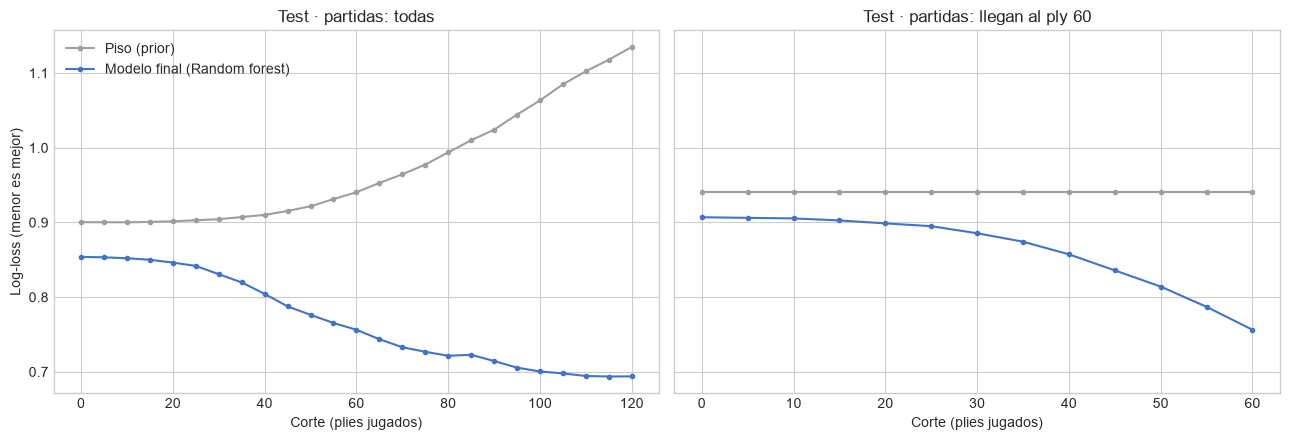

In [15]:
reaches_60 = test["GameUrl"].isin(set(test.loc[test["corte_ply"] == 60, "GameUrl"])).to_numpy()
curve_rows = []
for population, in_population, last in [("todas", np.ones(len(test), dtype=bool), max(CUTS)), ("llegan al ply 60", reaches_60, 60)]:
    for c in [c for c in CUTS if c <= last]:
        mask = in_population & (test_cut == c)
        curve_rows.append({"población": population, "corte_ply": c, "partidas": int(mask.sum()), **test_metrics(mask)})
curve = pd.DataFrame(curve_rows)
curve["mejora vs piso %"] = 100 * (1 - curve["log_loss"] / curve["log_loss piso"])
for population in ["todas", "llegan al ply 60"]:
    print(f"Población: {population}")
    shown = curve[(curve["población"] == population) & curve["corte_ply"].isin(REFERENCE_CUTS + [80, 100, 120])]
    display(shown.drop(columns="población").set_index("corte_ply"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, population in zip(axes, ["todas", "llegan al ply 60"]):
    sub = curve[curve["población"] == population]
    ax.plot(sub["corte_ply"], sub["log_loss piso"], color="#9e9e9e", marker="o", markersize=3, label="Piso (prior)")
    ax.plot(sub["corte_ply"], sub["log_loss"], color="#4472c4", marker="o", markersize=3, label=f"Modelo final ({CHOSEN_NAME})")
    ax.set(xlabel="Corte (plies jugados)", title=f"Test · partidas: {population}")
axes[0].set_ylabel("Log-loss (menor es mejor)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Lectura de la curva.** En las 319.284 filas de test, log-loss 0,795 frente a 0,936 del piso: 15,07 % menos. El F1 macro es 0,455 y el recall de Empate, 0,038. El modelo de la Entrega 3, sin los rivales, daba 0,804 (14,09 %).

- **Antes de empezar:** 0,854 frente a 0,900 (5,17 % de mejora; antes, 3,79 %). Sigue siendo una ventaja modesta, no certeza sobre el ganador.
- **Durante:** la mejora crece: 11,62 % al ply 40, 19,58 % al 60, 27,41 % al 80 y 38,86 % al 120. En ese último corte sólo quedan 2.789 partidas de test, por lo que no representa a las partidas que ya terminaron.
- **Población común:** las mismas 13.721 partidas que llegan al ply 60, en todos los cortes de la derecha. También hay mejora al empezar: 0,907 frente a 0,940 (3,56 %), y luego 8,83 % al ply 40 y 19,58 % al 60.

El piso global usa las proporciones de todas las filas de train. Empeora en cortes tardíos porque aumenta el peso de los empates entre las partidas supervivientes. No se debe atribuir toda la pendiente de la curva izquierda a haber visto más jugadas.

### Dónde se equivoca

La clase predicha es la de mayor probabilidad. La matriz normalizada **por fila** dice, de cada resultado real, qué se predijo (recall en la diagonal). La normalizada **por columna** dice, de cada predicción, qué pasó (precisión en la diagonal).

In [16]:
def confusion_table(mask, normalize):
    matrix = confusion_matrix(y_test[mask], predicted[mask], labels=RESULT_ORDER, normalize=normalize)
    return pd.DataFrame(matrix * 100, index=pd.Index(RESULT_ORDER, name="real"), columns=pd.Index(RESULT_ORDER, name="predicho"))


everything = np.ones(len(test), dtype=bool)
print("Todo el test, normalizada por fila (%): de cada resultado real, qué se predijo")
display(confusion_table(everything, "true"))
print("Todo el test, normalizada por columna (%): de cada predicción, qué pasó")
display(confusion_table(everything, "pred"))
print(classification_report(y_test, predicted, labels=RESULT_ORDER, digits=3, zero_division=0))
print("Sólo el corte 60, normalizada por fila (%)")
display(confusion_table(test_cut == 60, "true"))

Todo el test, normalizada por fila (%): de cada resultado real, qué se predijo


predicho,Gana Blancas,Empate,Gana Negras
real,,,
Gana Blancas,72.209,0.383,27.407
Empate,51.307,3.807,44.886
Gana Negras,36.464,0.346,63.190


Todo el test, normalizada por columna (%): de cada predicción, qué pasó


predicho,Gana Blancas,Empate,Gana Negras
real,,,
Gana Blancas,62.555,26.615,29.238
Empate,8.656,51.489,9.325
Gana Negras,28.789,21.896,61.437


              precision    recall  f1-score   support

Gana Blancas      0.626     0.722     0.670    151598
      Empate      0.515     0.038     0.071     29524
 Gana Negras      0.614     0.632     0.623    138162

    accuracy                          0.620    319284
   macro avg      0.585     0.464     0.455    319284
weighted avg      0.610     0.620     0.594    319284

Sólo el corte 60, normalizada por fila (%)


predicho,Gana Blancas,Empate,Gana Negras
real,,,
Gana Blancas,74.954,0.199,24.847
Empate,50.690,0.920,48.390
Gana Negras,26.592,0.136,73.272


In [17]:
# A concrete confusion, read from the board: rows from ply 60 on.
late = test_cut >= 60
late_frame = pd.DataFrame({
    "real": y_test[late], "predicho": predicted[late],
    "p_empate": proba_test[late, classes.index("Empate")],
    "balance": test.loc[late, "balance_material"].to_numpy(),
    # How the game ended: a post-game column, used here only to read the error, never as a feature.
    "final": test.loc[late, "GameUrl"].map(games.set_index("GameUrl")["Termination"]).to_numpy(),
})
display(late_frame.groupby("real").agg(
    filas=("real", "size"),
    p_empate_media=("p_empate", "mean"),
    predicho_empate=("predicho", lambda s: (s == "Empate").mean()),
    material_parejo=("balance", lambda s: (s.abs() <= 1).mean()),
).reindex(RESULT_ORDER))

decisive = late_frame[(late_frame["real"] != "Empate") & (late_frame["predicho"] != "Empate")]
flipped = decisive[decisive["real"] != decisive["predicho"]]
ahead = np.where(flipped["predicho"] == "Gana Blancas", flipped["balance"] > 0, flipped["balance"] < 0)
print(f"Desde el ply 60, el modelo erra el ganador en {len(flipped):,} de {len(decisive):,} filas de partidas decisivas "
      f"({len(flipped) / len(decisive) * 100:.1f} %). En esas, el bando que predijo iba arriba en material en el "
      f"{ahead.mean() * 100:.1f} % y estaban parejos en el {(flipped['balance'] == 0).mean() * 100:.1f} %.")
print("Cómo terminaron (% de filas):")
display(pd.DataFrame({
    "todas las decisivas": decisive["final"].value_counts(normalize=True),
    "erradas, con el predicho arriba en material": flipped.loc[ahead, "final"].value_counts(normalize=True),
}).mul(100).fillna(0).head(5))

,filas,p_empate_media,predicho_empate,material_parejo
real,,,,
Gana Blancas,43835,0.123,0.013,0.451
Empate,12985,0.204,0.086,0.611
Gana Negras,40334,0.124,0.012,0.438


Desde el ply 60, el modelo erra el ganador en 16,667 de 83,127 filas de partidas decisivas (20.1 %). En esas, el bando que predijo iba arriba en material en el 56.1 % y estaban parejos en el 25.6 %.
Cómo terminaron (% de filas):


,todas las decisivas,"erradas, con el predicho arriba en material"
final,,
time,40.918,50.711
resignation,32.174,26.119
checkmate,25.056,21.535
abandoned,1.853,1.635


**Lectura de la confusión.**

- **Empate:** recall 3,81 % y precisión 51,49 %. De los empates reales, 51,31 % se predicen blancas y 44,89 % negras. La probabilidad de tablas contiene información, aunque rara vez sea la mayor de las tres: desde el ply 60, las tablas reales reciben 0,204 de probabilidad media de empate, frente a 0,123 y 0,124 en las victorias de cada color. El material está parejo en 61,1 % de las filas que terminan en tablas, contra 45,1 % y 43,8 % en las decisivas.
- **Asimetría por color:** recall 72,21 % para blancas y 63,19 % para negras en todo el test. Al ply 60 se acercan: 74,95 % y 73,27 %. La ventaja blanca en la muestra favorece ese argmax cuando hay poca información; no se interpreta como un efecto causal del color estimado por el modelo.
- **Confusión concreta:** desde el ply 60 hay 16.667 errores de ganador en 83.127 filas decisivas con predicción decisiva (20,1 %). En 56,1 % de esos errores el bando elegido iba arriba en material; en 25,6 % estaban iguales. Entre los errores con el predicho arriba, 50,71 % terminan por tiempo, frente a 40,92 % del total decisivo. El reloj explica una parte observable de por qué una ventaja material no garantiza ganar. Son porcentajes de filas, no de partidas independientes.

### En qué se apoya

Importancia por permutación sobre una muestra de test, con la métrica declarada: cuánto empeora la log-loss si una columna se vuelve ruido. Es importancia **del modelo**, no un efecto causal. Para medir también columnas derivadas del historial se aplica primero el transformador causal y se permutan esas columnas ante el resto del pipeline ya ajustado; no se vuelve a entrenar ni se permutan los historiales como si fueran un predictor escalar. Las columnas que se parecen se reparten la importancia; por ejemplo, el material de cada bando y su diferencia.

Importancia por permutación sobre 20,000 filas de test (41 s)


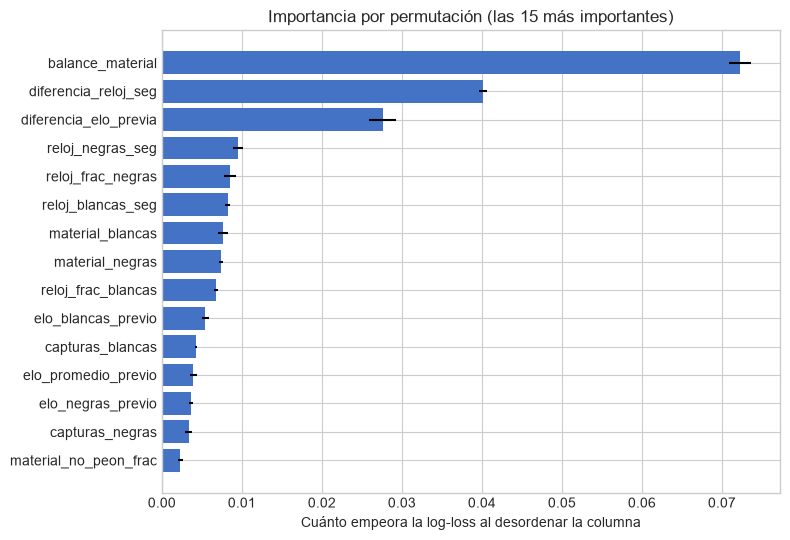

,media,desvío
balance_material,0.0722,0.0013
diferencia_reloj_seg,0.0401,0.0005
diferencia_elo_previa,0.0276,0.0017
reloj_negras_seg,0.0095,0.0006
reloj_frac_negras,0.0085,0.0007
reloj_blancas_seg,0.0082,0.0003
material_blancas,0.0077,0.0006
material_negras,0.0074,0.0003
reloj_frac_blancas,0.0067,0.0003
elo_blancas_previo,0.0054,0.0004


,media,desvío
enroco_negras,0.0001,0.0001
racha_negras,0.0001,0.0002
promociones,0.0000,0.0000
en_jaque,0.0000,0.0000
derechos_enroque_blancas,-0.0000,0.0000
derechos_enroque_negras,-0.0000,0.0000
tiempo_base_seg,-0.0001,0.0001
tendencia_rating_negras,-0.0001,0.0001


In [18]:
sample = test.sample(n=20_000, random_state=RANDOM_STATE)
started = time.perf_counter()
importance = permutation_importance(
    final_model[1:], final_model[0].transform(model_input_frame(sample, FINAL_COLUMNS)), sample["resultado"].astype(str),
    scoring="neg_log_loss", n_repeats=3, random_state=RANDOM_STATE,
)
importance = pd.DataFrame({"media": importance.importances_mean, "desvío": importance.importances_std}, index=FINAL_COLUMNS)
importance = importance.sort_values("media", ascending=False)
print(f"Importancia por permutación sobre {len(sample):,} filas de test ({time.perf_counter() - started:.0f} s)")

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top["media"], xerr=top["desvío"], color="#4472c4")
ax.set(xlabel="Cuánto empeora la log-loss al desordenar la columna", title="Importancia por permutación (las 15 más importantes)")
plt.tight_layout()
plt.show()
with pd.option_context("display.float_format", "{:.4f}".format):
    display(importance.head(10))
    display(importance.tail(8))

**Lectura.** `balance_material` domina: permutarlo empeora la log-loss en 0,0722 ± 0,0013. Le sigue `diferencia_reloj_seg`, 0,0401 ± 0,0005, y en tercer lugar `diferencia_elo_previa`, 0,0276 ± 0,0017: la columna nueva es la más importante de las que se conocen antes de mover. Después vienen los relojes, el material por lado y el rating previo de blancas (0,0054). Las columnas correlacionadas se reparten importancia, por lo que no se suman como efectos independientes.

**Por qué no es fuga.** El material se calcula con la posición hasta el corte, y `test_features_ignore_everything_after_the_cut` comprueba que cambiar la continuación no altera esas features. En el corte 0 el material es constante: la mejora temprana procede del contexto y del historial, no es una prueba de fuga por sí misma. El historial además exige cierres estrictamente anteriores y tiene pruebas de invariancia al futuro.

Al final quedan promociones, jaque, derechos de enroque, tiempo base y la tendencia del rating de negras con importancia prácticamente cero o ligeramente negativa. Eso describe su aporte marginal ante el resto de las columnas, no demuestra que carezcan de relación con el resultado. La forma entró por la ablación del grupo completo, no por tener una columna entre las diez primeras del ranking.

### La diferencia de rating, con todo lo demás fijo

Una comprobación de comportamiento sobre el modelo final, no una decisión: la posición inicial, los dos ratings conocidos con un día de antigüedad, sin forma reciente, en los tres ritmos. Se cambia sólo la diferencia de rating alrededor de cuatro promedios. La probabilidad de que ganen blancas no debería bajar cuando blancas tiene más rating que negras. Una celda cuenta como "con datos" si train tiene al menos 100 partidas de ese ritmo con un rating previo conocido a menos de 200 puntos del promedio; rapid 3000 no los tiene, porque la banda elite no juega rapid.


In [19]:
GRID_MEANS, GRID_DIFFERENCES = [1200, 1800, 2400, 3000], [-400, -200, 0, 200, 400]
GRID_RHYTHMS = {"bullet": 60, "blitz": 180, "rapid": 600}
known = PlayerHistoryTransformer(["elo_blancas_previo", "elo_negras_previo"]).fit_transform(
    attach_player_histories(train_games_frame, FINAL_HISTORIES))
rating_grid_rows = []
for rhythm, seconds in GRID_RHYTHMS.items():
    board, _ = game_cut_features("1. e4 *", [0], seconds, 0)
    in_rhythm = (train_games_frame["TimeClass"] == rhythm).to_numpy()
    for mean in GRID_MEANS:
        covered = known[in_rhythm].sub(mean).abs().le(200).any(axis=1).sum() >= 100
        for difference in GRID_DIFFERENCES:
            rating_grid_rows.append(dict(board[0], TimeClass=rhythm, tiempo_base_seg=seconds, incremento_seg=0, EsTorneo=False,
                                         elo_blancas_previo=mean + difference / 2, elo_negras_previo=mean - difference / 2,
                                         antiguedad_rating_dias_blancas=1.0, antiguedad_rating_dias_negras=1.0,
                                         ritmo=rhythm, promedio=mean, diferencia=difference, con_datos=covered))
rating_grid = pd.DataFrame(rating_grid_rows)
rating_grid["P(gana blancas)"] = final_model.predict_proba(model_input_frame(rating_grid, FINAL_COLUMNS))[:, classes.index("Gana Blancas")]
rating_grid_table = rating_grid.pivot_table(index=["ritmo", "promedio", "con_datos"], columns="diferencia", values="P(gana blancas)", sort=False)
display(rating_grid_table)
steps = np.diff(rating_grid_table.to_numpy(), axis=1)
with_data = rating_grid_table.index.get_level_values("con_datos").to_numpy()
print(f"Inversiones (sube la diferencia y baja blancas): {(steps[with_data] < -1e-9).sum()} de {steps[with_data].size} pasos con datos; "
      f"{(steps < -1e-9).sum()} de {steps.size} en total")


diferencia                 -400  -200   0     200   400
ritmo  promedio con_datos                              
bullet 1200     True      0.155 0.310 0.521 0.596 0.717
       1800     True      0.139 0.286 0.537 0.595 0.695
       2400     True      0.191 0.369 0.493 0.643 0.696
       3000     True      0.120 0.313 0.459 0.682 0.704
blitz  1200     True      0.164 0.284 0.499 0.614 0.755
       1800     True      0.143 0.260 0.537 0.618 0.731
       2400     True      0.192 0.343 0.523 0.658 0.718
       3000     True      0.118 0.273 0.447 0.673 0.713
rapid  1200     True      0.154 0.241 0.481 0.668 0.775
       1800     True      0.142 0.226 0.476 0.648 0.739
       2400     True      0.179 0.306 0.474 0.686 0.729
       3000     False     0.116 0.250 0.356 0.631 0.678

Inversiones (sube la diferencia y baja blancas): 0 de 44 pasos con datos; 0 de 48 en total


**Lectura.** Ninguna inversión: en los 44 pasos con datos (y en los 48 contando rapid 3000), subir la diferencia de rating nunca baja la probabilidad de blancas. Con −400 la probabilidad de blancas queda entre 0,12 y 0,19, con 0 entre 0,45 y 0,54 y con +400 entre 0,70 y 0,78. El modelo de la Entrega 3, con la misma grilla, tenía 16 inversiones en 44 pasos y casi no se movía (de 0,42 a 0,58).

Es una grilla de control, no una medida de calibración: muestra que el modelo responde en la dirección esperada al nivel relativo, no que esas probabilidades sean exactas. La prueba queda también en `tests/test_model_realism.py`.

## 9 · ¿Sirve en cualquier jugada?

El modelo se entrenó con un corte cada 5 plies, pero la app predice en todas las jugadas. Como `corte_ply` es una columna numérica, el modelo puede evaluarse en el ply 47 aunque nunca haya visto ese valor. Hay que comprobar que ahí rinde como en los cortes vecinos.

Sobre 1.000 partidas de test se usa `predecir()` de `src/predict.py`, la misma función que va a usar la app, ply por ply. Primero se verifica que, en los plies del dataset, `predecir()` dé exactamente las mismas probabilidades que el camino de entrenamiento: así el código de la app no puede desviarse del modelo evaluado. Después se compara la log-loss de los plies intermedios con la que se obtiene interpolando entre los cortes vecinos. No es una decisión: es una medición más del modelo final.

In [20]:
check_games = sorted(pd.Series(sorted(test_games)).sample(n=1_000, random_state=RANDOM_STATE))
wanted = set(check_games)
pgns = {}
for path in raw_paths.values():
    with Path(path).open(encoding="utf-8") as file:
        for game in json.load(file).get("games", []):
            if game.get("url") in wanted:
                pgns.setdefault(game["url"], game["pgn"])
assert len(pgns) == len(wanted), "Falta el PGN crudo de alguna partida"

in_memory = {"resultado": final_model, "columnas": FINAL_COLUMNS}
context = attach_player_histories(games, FINAL_HISTORIES).set_index("GameUrl").loc[
    check_games, ["TimeClass", "tiempo_base_seg", "incremento_seg", "EsTorneo", *HISTORY_INPUTS]]
started = time.perf_counter()
per_ply = pd.concat(
    [predecir(pgns[url], context.loc[url].to_dict(), in_memory).assign(GameUrl=url) for url in check_games],
    ignore_index=True,
)
rows_before = len(per_ply)
per_ply = per_ply.merge(games[["GameUrl", "resultado", "cantidad_jugadas"]], on="GameUrl", how="left", validate="many_to_one")
assert len(per_ply) == rows_before, "Fan-out detectado al unir el resultado"
print(f"{len(per_ply):,} predicciones (una por ply) de {len(check_games):,} partidas en {time.perf_counter() - started:.0f} s")

# Same features, same model: at the dataset cuts, predecir must reproduce the training-path probabilities.
test_rows = test[["GameUrl", "corte_ply"]].reset_index(names="fila")
on_cuts = per_ply.merge(test_rows, left_on=["GameUrl", "ply"], right_on=["GameUrl", "corte_ply"], how="inner", validate="one_to_one")
assert len(on_cuts) == int(test["GameUrl"].isin(check_games).sum()), "Faltan cortes al verificar la app"
for label in RESULT_ORDER:
    np.testing.assert_allclose(on_cuts[label].to_numpy(), proba_test[on_cuts["fila"].to_numpy(), classes.index(label)], atol=1e-9)
print(f"predecir() reproduce las {len(on_cuts):,} predicciones del dataset en los plies de corte")

78,605 predicciones (una por ply) de 1,000 partidas en 94 s
predecir() reproduce las 15,584 predicciones del dataset en los plies de corte


641 partidas que llegan al ply 60. En los plies intermedios, log-loss media 0.9048 contra 0.9049 interpolando los cortes vecinos (diferencia media -0.0001; la mayor, en valor absoluto, 0.0173)


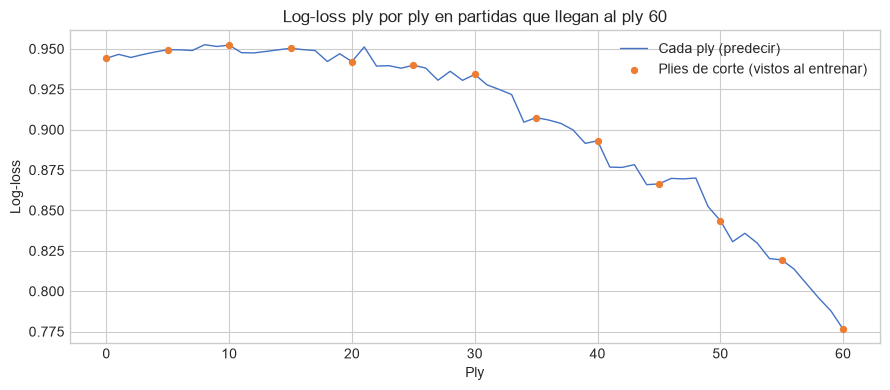

In [21]:
def ply_log_loss(frame):
    return log_loss(frame["resultado"], frame[classes].to_numpy(), labels=classes)


# Common population, as in section 8: games still going at ply 60, so every ply compares the same games.
common = per_ply[(per_ply["cantidad_jugadas"] > 60) & (per_ply["ply"] <= 60)]
by_ply = common.groupby("ply")[["resultado", *classes]].apply(ply_log_loss)
on_grid = by_ply[by_ply.index % 5 == 0]
interpolated = pd.Series(np.interp(by_ply.index, on_grid.index, on_grid.to_numpy()), index=by_ply.index)
off_grid = by_ply.index % 5 != 0
gap = (by_ply - interpolated)[off_grid]
print(f"{common['GameUrl'].nunique()} partidas que llegan al ply 60. En los plies intermedios, log-loss media {by_ply[off_grid].mean():.4f} "
      f"contra {interpolated[off_grid].mean():.4f} interpolando los cortes vecinos "
      f"(diferencia media {gap.mean():+.4f}; la mayor, en valor absoluto, {gap.abs().max():.4f})")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_ply.index, by_ply.to_numpy(), color="#4472c4", linewidth=1, label="Cada ply (predecir)")
ax.scatter(on_grid.index, on_grid.to_numpy(), color="#ed7d31", zorder=3, s=18, label="Plies de corte (vistos al entrenar)")
ax.set(xlabel="Ply", ylabel="Log-loss", title="Log-loss ply por ply en partidas que llegan al ply 60")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.** `predecir()` genera 78.605 predicciones de 1.000 partidas y reproduce las 15.584 probabilidades de los cortes del dataset hasta una tolerancia de 1e-9. También usa el mismo transformador de historial, con los mismos historiales (incluido el rating de los rivales).

Sobre 641 partidas que llegan al ply 60, la log-loss media de plies intermedios es 0,9048 frente a 0,9049 interpolando los cortes vecinos: diferencia media −0,0001 y máxima absoluta 0,0173. En esta muestra los puntos intermedios se comportan de forma comparable, sin demostrar idéntico rendimiento en toda posición posible ni fuera del rango entrenado.

## 10 · Objetivo secundario: la duración restante

Cuántos medio-movimientos faltan desde el corte (`plies_restantes`). Es una regresión, y se mide con el **error absoluto medio** (MAE), que se lee en plies: "le erramos por N plies en promedio". El piso es `DummyRegressor(strategy="median")` y el modelo simple, una regresión lineal con el mismo preprocesamiento. Se compara con un gradient boosting que optimiza el error absoluto, con la misma validación y las mismas columnas del clasificador final. No hay grilla propia: si el boosting fue el elegido para el resultado, usa esos hiperparámetros.

In [22]:
def make_regressor(family, columns):
    categorical = [c for c in columns if c in CATEGORICAL]
    numeric = [c for c in columns if c not in CATEGORICAL]
    if family == "mediana":
        return DummyRegressor(strategy="median")
    if family == "lineal":
        prep = ColumnTransformer([
            ("categoricas", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("numericas", Pipeline([
                ("imputar", SimpleImputer(strategy="median", add_indicator=True)), ("escalar", StandardScaler()),
            ]), numeric),
        ])
        return Pipeline([("historial", PlayerHistoryTransformer(columns)), ("prep", prep), ("modelo", LinearRegression())])
    if family == "boosting":
        prep = ColumnTransformer(
            [("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
             ("numericas", "passthrough", numeric)],
            verbose_feature_names_out=False,
        ).set_output(transform="pandas")
        model = HistGradientBoostingRegressor(
            loss="absolute_error", categorical_features=categorical, early_stopping=False, random_state=RANDOM_STATE
        )
        return Pipeline([("historial", PlayerHistoryTransformer(columns)), ("prep", prep), ("modelo", model)])
    raise ValueError(f"Familia desconocida: {family}")


DURATION_PARAMS = {k: v for k, v in BEST_PARAMS.items() if k != "modelo__class_weight"} if CHOSEN_FAMILY == "boosting" else {}
REGRESSORS = {"Piso (mediana)": "mediana", "Regresión lineal": "lineal", "Gradient boosting": "boosting"}
X_cv_final = model_input_frame(cv_final, FINAL_COLUMNS)
duration_cv = {}
for name, family in REGRESSORS.items():
    regressor = make_regressor(family, FINAL_COLUMNS)
    if family == "boosting":
        regressor.set_params(**DURATION_PARAMS)
    result = cross_validate(regressor, X_cv_final, cv_data["plies_restantes"].to_numpy(dtype=float), cv=FOLDS,
                            scoring="neg_mean_absolute_error", return_train_score=True)
    duration_cv[name] = {"MAE": -result["test_score"].mean(), "± MAE": result["test_score"].std(),
                         "MAE train": -result["train_score"].mean(), "_folds": -result["test_score"]}
display(pd.DataFrame(duration_cv).T.drop(columns="_folds"))

DURATION_NAME = SIMPLE_REGRESSOR = "Regresión lineal"
diff = duration_cv["Gradient boosting"]["_folds"] - duration_cv[SIMPLE_REGRESSOR]["_folds"]
if diff.mean() < -diff.std(ddof=1):
    DURATION_NAME = "Gradient boosting"
print(f"Boosting − lineal: {diff.mean():+.2f} ± {diff.std(ddof=1):.2f} plies por pedazo → regresor elegido: {DURATION_NAME}")

,MAE,± MAE,MAE train
Piso (mediana),27.643,1.087,26.074
Regresión lineal,23.470,0.889,21.584
Gradient boosting,22.885,0.817,18.760


Boosting − lineal: -0.59 ± 0.14 plies por pedazo → regresor elegido: Gradient boosting


,MAE piso,MAE modelo,mejora %
corte_ply,,,
todos,28.357,22.889,19.284
0,40.857,27.203,33.419
10,34.332,26.937,21.539
20,29.719,26.272,11.597
30,26.963,25.201,6.537
40,25.601,23.740,7.267
60,24.800,20.448,17.548
80,24.372,17.717,27.304
100,24.382,15.554,36.209


,filas,MAE,sesgo_medio
tramo real,,,
1-10,35839,21.013,20.825
11-20,36935,17.864,16.954
21-40,73363,14.482,9.814
41-60,64522,14.106,-1.817
61-100,76651,24.722,-22.625
más de 100,31974,63.416,-63.416


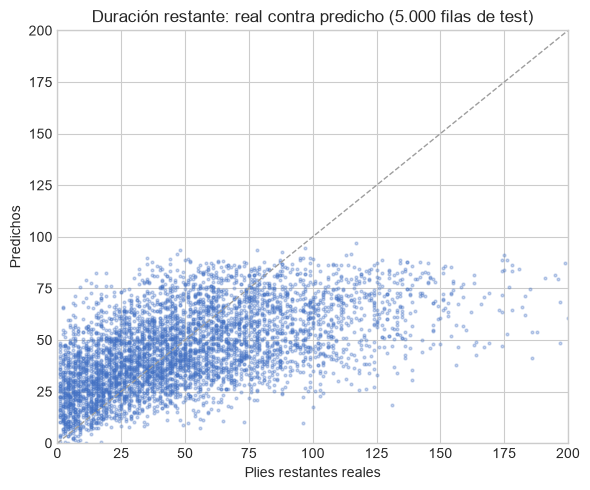

In [23]:
y_train_dur, y_test_dur = train["plies_restantes"].to_numpy(dtype=float), test["plies_restantes"].to_numpy(dtype=float)
final_regressor = make_regressor(REGRESSORS[DURATION_NAME], FINAL_COLUMNS)
if REGRESSORS[DURATION_NAME] == "boosting":
    final_regressor.set_params(**DURATION_PARAMS)
final_regressor.fit(X_train, y_train_dur)
floor_regressor = make_regressor("mediana", FINAL_COLUMNS).fit(X_train, y_train_dur)
pred_dur, pred_floor_dur = final_regressor.predict(X_test), floor_regressor.predict(X_test)

duration_rows = [{"corte_ply": "todos", "MAE piso": mean_absolute_error(y_test_dur, pred_floor_dur),
                  "MAE modelo": mean_absolute_error(y_test_dur, pred_dur)}]
for c in REFERENCE_CUTS + [80, 100, 120]:
    mask = test_cut == c
    duration_rows.append({"corte_ply": c, "MAE piso": mean_absolute_error(y_test_dur[mask], pred_floor_dur[mask]),
                          "MAE modelo": mean_absolute_error(y_test_dur[mask], pred_dur[mask])})
duration_test = pd.DataFrame(duration_rows).set_index("corte_ply")
duration_test["mejora %"] = 100 * (1 - duration_test["MAE modelo"] / duration_test["MAE piso"])
display(duration_test)

# Real against predicted, and in which range of the target the error is largest.
ranges = pd.cut(y_test_dur, bins=[0, 10, 20, 40, 60, 100, 1000], labels=["1-10", "11-20", "21-40", "41-60", "61-100", "más de 100"])
by_range = pd.DataFrame({"tramo real": ranges, "error": np.abs(pred_dur - y_test_dur), "sesgo": pred_dur - y_test_dur})
display(by_range.groupby("tramo real", observed=True).agg(filas=("error", "size"), MAE=("error", "mean"), sesgo_medio=("sesgo", "mean")))

fig, ax = plt.subplots(figsize=(6, 5))
shown = np.random.default_rng(RANDOM_STATE).choice(len(y_test_dur), size=5_000, replace=False)
ax.scatter(y_test_dur[shown], pred_dur[shown], s=4, alpha=0.3, color="#4472c4")
ax.plot([0, 200], [0, 200], color="#9e9e9e", linestyle="--", linewidth=1)
ax.set(xlim=(0, 200), ylim=(0, 200), xlabel="Plies restantes reales", ylabel="Predichos",
       title="Duración restante: real contra predicho (5.000 filas de test)")
plt.tight_layout()
plt.show()

**Lectura.**

- **CV:** mediana 27,643 ± 1,087 plies; lineal 23,470 ± 0,889; boosting 22,885 ± 0,817. El boosting mejora a la lineal por 0,59 ± 0,14 plies pedazo a pedazo y queda elegido por la regla.
- **Test:** MAE 22,889 frente a 28,357 del piso, 19,28 % menos error.
- **Por corte:** mejora 33,42 % antes de empezar, 6,54 % al ply 30, 17,55 % al 60 y 46,60 % al 120. El contexto y el momento de la partida ya permiten ajustar el horizonte típico, sin anticipar el movimiento que la termina.
- **Dónde falla:** cuando quedan 1–10 plies, sobreestima 20,83 de media; cuando quedan más de 100, subestima 63,42. El MAE es 21,01 y 63,42 en esos tramos. El modelo concentra sus predicciones alrededor de duraciones típicas y falla en los extremos.

Es un objetivo secundario, con las columnas elegidas para el resultado y sin grilla propia de regresión. No se presenta como un modelo de duración completamente optimizado.

## 11 · Modelo guardado para la app

Se guarda un solo archivo con los dos pipelines (resultado y plies restantes) y la lista de columnas. Después se vuelve a cargar desde disco y se usa con `predecir()`, como lo va a hacer la app. `models/` no se versiona: lo regenera este notebook.

Guardado en models/modelo_en_vivo.joblib (132.0 MB)


Ejemplo: bullet, 70 plies, Gana Negras por checkmate. El ganador llegó a 2.4 % en el ply 63.


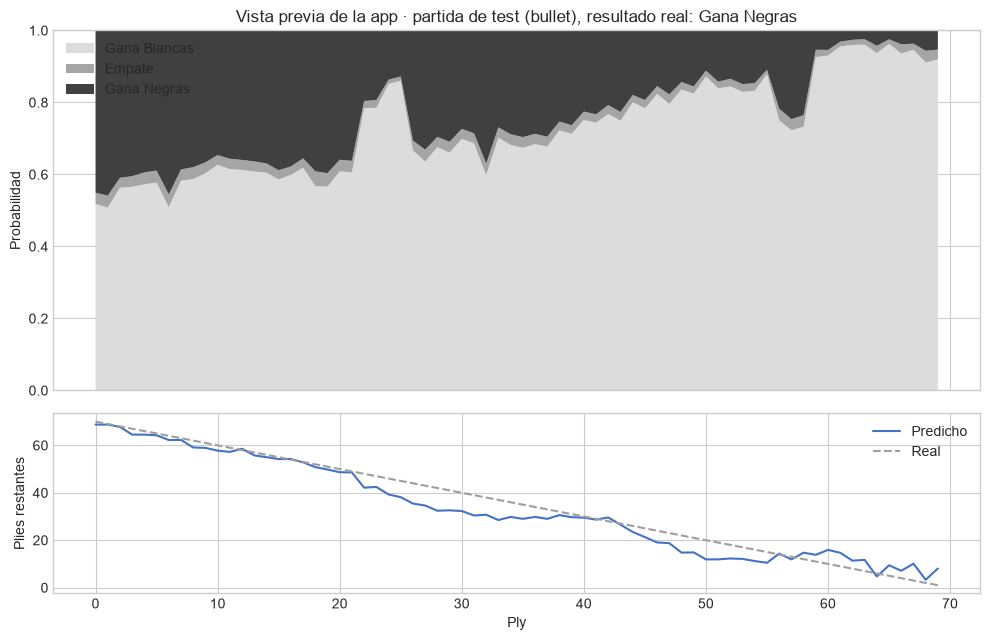

In [24]:
train_ratings = PlayerHistoryTransformer(["elo_blancas_previo", "elo_negras_previo"]).fit_transform(
    attach_player_histories(games[games["GameUrl"].isin(train_games)], FINAL_HISTORIES))
artifact = {
    "resultado": final_model,
    "plies_restantes": final_regressor,
    "columnas": FINAL_COLUMNS,
    "familia": CHOSEN_NAME,
    "historial_en_pipeline": True,
    # Histories include rating-only observations of opponents (section 7): callers must build them the same way.
    "historial_rivales": USE_RIVALS,
    "partidas_dataset": len(games),
    "hiperparametros": BEST_PARAMS,
    "entrenado_hasta": split_time.isoformat(),
    "cortes_entrenamiento": CUTS,
    # The ratings the model saw: the app warns when a game falls outside them.
    "rango_rating": [float(train_ratings.min().min()), float(train_ratings.max().max())],
}
model_path = PROJECT_ROOT / MODEL_PATH
model_path.parent.mkdir(exist_ok=True)
joblib.dump(artifact, model_path, compress=3)
reloaded = cargar_modelo(model_path)
print(f"Guardado en {MODEL_PATH} ({model_path.stat().st_size / 1e6:.1f} MB)")

# Preview of what the app shows: the test game of the sample where the eventual winner fell lowest.
winner_proba = per_ply.apply(lambda row: row[row["resultado"]], axis=1)
decisive_long = per_ply[(per_ply["resultado"] != "Empate") & (per_ply["cantidad_jugadas"] >= 60)]
low_point = winner_proba.loc[decisive_long.index].groupby(decisive_long["GameUrl"]).min()
example_url = low_point.sort_values(kind="stable").index[0]
example = predecir(pgns[example_url], context.loc[example_url].to_dict(), reloaded)
np.testing.assert_allclose(
    example[RESULT_ORDER].to_numpy(), per_ply.loc[per_ply["GameUrl"] == example_url, RESULT_ORDER].to_numpy(), atol=1e-9
)
outcome = games.set_index("GameUrl").loc[example_url]
lowest = example.loc[example[outcome["resultado"]].idxmin()]
print(f"Ejemplo: {outcome['TimeClass']}, {outcome['cantidad_jugadas']} plies, {outcome['resultado']} por {outcome['Termination']}. "
      f"El ganador llegó a {lowest[outcome['resultado']] * 100:.1f} % en el ply {int(lowest['ply'])}.")

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, height_ratios=[2, 1])
axes[0].stackplot(example["ply"], example["Gana Blancas"], example["Empate"], example["Gana Negras"],
                  labels=RESULT_ORDER, colors=["#dcdcdc", "#a5a5a5", "#404040"])
axes[0].set(ylabel="Probabilidad", ylim=(0, 1),
            title=f"Vista previa de la app · partida de test ({outcome['TimeClass']}), resultado real: {outcome['resultado']}")
axes[0].legend(loc="upper left")
axes[1].plot(example["ply"], example["plies_restantes"], color="#4472c4", label="Predicho")
axes[1].plot(example["ply"], outcome["cantidad_jugadas"] - example["ply"], color="#9e9e9e", linestyle="--", label="Real")
axes[1].set(xlabel="Ply", ylabel="Plies restantes")
axes[1].legend()
plt.tight_layout()
plt.show()

**Lectura.** El artefacto pesa 132,0 MB y conserva los dos pipelines, las 40 columnas finales y la marca `historial_rivales`: quien lo use tiene que armar los historiales de la misma forma. Se recarga y reproduce las probabilidades del modelo en memoria.

El ejemplo es una partida bullet de 70 plies que ganan negras por mate. El modelo llegó a darles sólo 2,4 % en el ply 63. Se eligió precisamente por ser el mínimo más extremo del ganador real en la muestra: ilustra una limitación, no una partida representativa. El material y el reloj describen el presente, pero no garantizan anticipar la táctica que da vuelta el resultado. La segunda curva compara la duración predicha con la real.

## 12 · Conclusiones

**Métrica.** Log-loss porque la app muestra probabilidades y el error caro es mostrarlas muy seguras y equivocadas. F1 macro y recall hacen visible al empate.

**Contra el piso.** En test, 0,795 frente a 0,936 (15,07 % menos log-loss). Hay mejora modesta antes de mover (5,17 %) y también sobre población común (3,56 %). Crece al avanzar: 19,58 % al ply 60 y 38,86 % al 120. Son reducciones de log-loss, no puntos de accuracy.

**Validación y familia.** Temporal por partida, con todos los cierres de train anteriores al primer inicio de validación. El bosque supera a la logística por 0,0205 ± 0,0058; el boosting por defecto no supera la regla. Al azar todas las filas comparten partida con train y dan 0,811 frente a 0,823 agrupando por partida. El diagnóstico por cuenta ancla da 0,828, con la limitación de rivales repetidos.

**Columnas.** Quedan 40: contexto, posición/relojes de la base, forma reciente sin pausas ni sesión, y el rating de los dos lados con su antigüedad, diferencia y promedio. Rating y forma se derivan dentro del Pipeline con `EndTime < StartTime`.

**Ratings de los rivales (corrección posterior a la Entrega 3).** El modelo de la Entrega 3 casi nunca vio los dos ratings (185 de 80.314 partidas de train) y en la app más diferencia de rating podía bajar la probabilidad del favorito. Con el rating de los rivales que ya traían los JSON, la cobertura sube a 41,7 %; con la diferencia y el promedio, la variante D mejora la CV por −0,0053 ± 0,0022 y el corte 0 por −0,0090 ± 0,0029, y la grilla de control queda sin inversiones (antes, 16 de 44 pasos). En test: 0,795 frente a 0,804 del modelo anterior; ese período ya estaba usado y no decidió nada. La auditoría encontró 1.345 observaciones propias cuyo cierre anterior no era anterior al inicio actual; se consulta un historial más antiguo en lugar de asumir que el `shift()` ya era seguro.

**Confusión e interpretación.** El material es la columna de mayor importancia (0,0722 de log-loss al permutarlo), seguido por diferencia de reloj (0,0401) y diferencia de rating (0,0276). Desde ply 60, el 56,1 % de los errores de ganador eligieron un bando que iba arriba en material; 50,71 % de esos errores terminaron por tiempo. El empate tiene 3,81 % de recall, aunque sus probabilidades distinguen mejor las partidas con cara de tablas.

**Duración.** El boosting secundario erra 22,89 plies en test, frente a 28,36 del piso. Sobreestima los finales próximos y subestima los horizontes largos.

### Lo que probamos y no quedó

- **Balancear Empate:** recall 0,026 → 0,451, pero cuesta +0,1387 ± 0,0156 de log-loss. No se balancea.
- **Calidad de posición adicional:** material colgado y movilidad por bando mejoran algo globalmente, pero empeoran el corte 0 más que lo permitido. Ataques al rey y peones pasados tampoco pasan la regla. No se afirma que no tengan señal.
- **Estilo con el reloj:** +0,0005 ± 0,0023 global, sin mejora más allá de la variación. No entra.
- **Matchup:** +0,0017 ± 0,0011 global, sin mejora. No entra.
- **Ratings de rivales sin diferencia (B):** −0,0008 ± 0,0025 global, dentro de la variación. Entra recién con la diferencia y el promedio (C y D).
- **Boosting por defecto:** brecha de train/validación y variación alta. No se ajustó porque no fue la familia elegida; no se concluye que cualquier configuración sea peor.

### Limitaciones

- 120 cuentas por cupos de ELO, no una muestra de toda Chess.com; no hay rapid en la banda elite.
- El historial completo (forma, racha) normalmente sólo existe para un lado; del rival se conoce un rating suelto, a veces viejo (de ahí la antigüedad). En 58,3 % de las partidas de train falta el rating de al menos un lado. El imputador aprende sus valores sólo en cada train.
- Una partida larga aporta más filas; las métricas por corte requieren controlar la población superviviente.
- Los grupos se prueban contra la base y la regla conjunta es conservadora con el corte 0; no se exploran todas las combinaciones.
- Entrenamiento hasta ply 120; más allá se extrapola.
- El test ya había sido observado en el 03 y en una versión previa del 04. Se repitió por corregir el cálculo temporal; no es un período nuevo y no se eligió por su resultado.
- La duración es secundaria, comparte columnas con clasificación y no tiene ajuste propio de hiperparámetros.

La última celda verifica integridad, separación y round-trip. Los tests de realismo del artefacto se encuentran en `tests/test_model_realism.py`: proporciones iniciales, dama ganada, desventaja de reloj, ganador cerca del final, calibración por clase y grilla de diferencia de rating.

**Pruebas externas del artefacto final.** En la suite, el test de dama ganada falla en sus dos subcasos. En dos secuencias legales de apertura, el balance pasa de 0 a +9 para blancas y de 0 a −9 para negras, respectivamente. La probabilidad del beneficiado pasa de 48,52 % a 60,10 % y de 46,34 % a 52,63 %: +11,58 y +6,29 puntos, por debajo del contrato de +15 puntos (el modelo de la Entrega 3 daba +9,02 y +10,34). La extracción del material es correcta y la dirección se cumple; la magnitud exigida no. Se conserva el umbral y se informa el fallo, sin ajustar el modelo sobre estos ejemplos. Pasan las pruebas de proporciones iniciales, reloj, ganador cerca del final en promedio, calibración por clase (tolerancia de ocho puntos) y la grilla de diferencia de rating. Aprobar métricas agregadas no garantiza sensibilidad suficiente a cada táctica individual.


In [25]:
assert not set(LEAKY) & set(FINAL_COLUMNS), "Una columna con fuga entró al modelo final"
assert set(train["GameUrl"]).isdisjoint(test["GameUrl"])
assert games.loc[games["GameUrl"].isin(train_games), "EndTime"].max() < games.loc[games["GameUrl"].isin(test_games), "StartTime"].min(), \
    "Una partida de train termina después de que empieza una de test"
assert set(cv_data["GameUrl"]) <= train_games, "La validación cruzada vio una partida de test"
assert np.isfinite(curve["log_loss"]).all()
# Sanity bound: overall, the prior floor can never be worse than a uniform guess (ln 3).
assert log_loss(y_test, proba_floor, labels=floor_model.classes_) < np.log(3)
assert reloaded["columnas"] == FINAL_COLUMNS and list(reloaded["resultado"].classes_) == sorted(RESULT_ORDER)
print(f"Todos los chequeos pasaron. Tiempo total: {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min")

Todos los chequeos pasaron. Tiempo total: 54.4 min


## 13 · Exportación para la app

La app de la Entrega 4 tiene que mostrar lo mismo que este notebook. En lugar de copiar
números a mano, se guardan las tablas que ya se calcularon arriba. `python -m src.build_app` las lee para
armar los gráficos, recalcula el test con el modelo guardado y falla si no da lo mismo que
acá. El reporte queda en `models/` y no se versiona, igual que el modelo.

In [26]:
from src.app_data import REPORTE_MODELADO, guardar_reporte, tabla

# Every number the app shows about the model comes from these tables, computed above.
reporte = {
    "corrida": {
        "partidas": len(games), "filas_cortes": len(cuts), "corte_temporal": split_time.isoformat(),
        "partidas_train": len(train_games), "partidas_test": len(test_games),
        "filas_train": len(train), "filas_test": len(test), "folds": N_SPLITS, "fraccion_cv": CV_GAME_FRACTION,
    },
    "comparacion": tabla(summarize(comparison)),
    "comparacion_por_fold": tabla(pd.DataFrame({name: s["log_loss"] for name, s in comparison.items()})),
    "decision": tabla(decision),
    "elegido": CHOSEN_NAME,
    "grilla": tabla(grid_table.sort_values("log_loss")),
    "mejores_hiperparametros": {k.removeprefix("modelo__"): v for k, v in BEST_PARAMS.items()},
    "balanceo": {"diferencia": float(balance_diff.mean()), "desvio": float(balance_diff.std(ddof=1)),
                 "recall_empate_sin": float(tuned_scores["recall_empate"].mean()),
                 "recall_empate_con": float(balanced_scores["recall_empate"].mean()), "se_balancea": bool(USE_BALANCED)},
    "columnas_por_grupo": tabla(ablation_table),
    "ratings_rivales": tabla(rival_table),
    "columnas_finales": FINAL_COLUMNS,
    "columnas_con_fuga": LEAKY,
    "test": overall.to_dict(),
    "test_por_corte": tabla(curve.set_index("corte_ply")),
    "confusion_por_fila": tabla(confusion_table(everything, "true")),
    "confusion_por_columna": tabla(confusion_table(everything, "pred")),
    "errores_desde_ply_60": {"filas_decisivas": len(decisive), "erradas": len(flipped),
                             "predicho_arriba_en_material": float(ahead.mean()),
                             "terminaron_por_tiempo": float(flipped.loc[ahead, "final"].eq("time").mean())},
    "importancia": tabla(importance.rename_axis("columna")),
    "duracion_test": tabla(duration_test),
}
guardar_reporte(reporte, PROJECT_ROOT / REPORTE_MODELADO)

print(f"Reporte en {REPORTE_MODELADO}")

Reporte en models/reporte_modelado.json
